In [ ]:

!pip install -q datasets gensim indic-nlp-library \
    scikit-learn scipy pandas numpy matplotlib seaborn


In [ ]:

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset
from gensim.models import FastText
from scipy.stats import spearmanr
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.manifold import TSNE

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

from datasets import load_dataset

dataset = load_dataset(
    "rony000013/indiccorpV2-5k"
)

print(dataset)


README.md:   0%|          | 0.00/1.86k [00:00<?, ?B/s]

data.parquet: reconstructing file:   0%|          |  0.00B / 28.8MB            

data.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/118243 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['language', 'code', 'text'],
        num_rows: 118243
    })
})


In [ ]:

print("Dataset splits:")
print(dataset.keys())

for split in dataset.keys():
    print("\nSplit:", split)
    print("Number of rows:", len(dataset[split]))
    print("Columns:", dataset[split].column_names)
    print("First example:")
    print(dataset[split][0])


Dataset splits:
dict_keys(['train'])

Split: train
Number of rows: 118243
Columns: ['language', 'code', 'text']
First example:
{'language': 'Assamese', 'code': 'as', 'text': 'ঘটনাৰ বিৱৰণি মতে বোকাকাতৰ কৈলাখাতত নিয়মিতভাৱে বহা জুৱাৰ আড্ডাত শুকুৰবাৰে অৰ্থাৎ ১৯ এপ্ৰিলৰ নিশা প্ৰাক্তন সেনা জোৱানজনে গুলী ফুটাই সন্ত্ৰাসৰ সৃষ্টি কৰে। বোকাখাতৰ কৈলাখাতত নিয়মিতভাৱে বহা এই জুৱাৰ থলীত জুৱাৰীৰ পৰা ধন লুটাৰ স্বাৰ্থতে ধৃত প্ৰাক্তন সেনা জোৱান মোহন কছাৰীয়ে গুলী ফুটাই সন্ত্ৰাস সৃষ্টি কৰে।'}


In [ ]:

os.makedirs("FOVL_Project", exist_ok=True)

with open("FOVL_Project/dataset_info.txt", "w") as f:
    f.write(str(dataset))

print("Dataset information saved!")


Dataset information saved!


In [ ]:
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['language', 'code', 'text'],
        num_rows: 118243
    })
})


In [ ]:
print(dataset["train"].column_names)
print(dataset["train"][0])

['language', 'code', 'text']
{'language': 'Assamese', 'code': 'as', 'text': 'ঘটনাৰ বিৱৰণি মতে বোকাকাতৰ কৈলাখাতত নিয়মিতভাৱে বহা জুৱাৰ আড্ডাত শুকুৰবাৰে অৰ্থাৎ ১৯ এপ্ৰিলৰ নিশা প্ৰাক্তন সেনা জোৱানজনে গুলী ফুটাই সন্ত্ৰাসৰ সৃষ্টি কৰে। বোকাখাতৰ কৈলাখাতত নিয়মিতভাৱে বহা এই জুৱাৰ থলীত জুৱাৰীৰ পৰা ধন লুটাৰ স্বাৰ্থতে ধৃত প্ৰাক্তন সেনা জোৱান মোহন কছাৰীয়ে গুলী ফুটাই সন্ত্ৰাস সৃষ্টি কৰে।'}


In [ ]:

df = dataset["train"].to_pandas()

print("TOTAL ROWS:", len(df))

print("\nTOTAL LANGUAGES:", df["language"].nunique())

print("\nLANGUAGE DISTRIBUTION:")
print(df["language"].value_counts())

print("\nLANGUAGE AND CODE:")
print(df[["language", "code"]].drop_duplicates().to_string(index=False))

print("\nFIRST DATA SAMPLE:")
print(df.iloc[0].to_dict())


TOTAL ROWS: 118243

TOTAL LANGUAGES: 24

LANGUAGE DISTRIBUTION:
language
Assamese          5000
Bodo              5000
Bengali           5000
Dogri             5000
English           5000
Konkani (Goan)    5000
Gujarati          5000
Hindi             5000
Khasi             5000
Kannada           5000
Maithili          5000
Malayalam         5000
Marathi           5000
Manipuri          5000
Nepali            5000
Odia              5000
Sindhi            5000
Punjabi           5000
Sanskrit          5000
Santali           5000
Telugu            5000
Tamil             5000
Urdu              5000
Kashmiri          3243
Name: count, dtype: int64

LANGUAGE AND CODE:
      language code
      Assamese   as
          Bodo   bd
       Bengali   bn
         Dogri   dg
       English   en
Konkani (Goan)  gom
      Gujarati   gu
         Hindi   hi
         Khasi  kha
       Kannada   kn
      Kashmiri   ks
      Maithili  mai
     Malayalam   ml
      Manipuri  mni
       Marathi   mr
        N

In [ ]:

import re
import unicodedata
import os
import json
from collections import defaultdict

print("Preprocessing libraries ready!")


Preprocessing libraries ready!


In [ ]:

def clean_text(text):

    if not isinstance(text, str):
        return ""

    # Normalize Unicode
    text = unicodedata.normalize("NFC", text)

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    cleaned_chars = []

    for char in text:

        category = unicodedata.category(char)

        # Preserve letters, marks, numbers and whitespace
        if category.startswith(("L", "M", "N")):
            cleaned_chars.append(char)

        elif char.isspace():
            cleaned_chars.append(" ")

        else:
            cleaned_chars.append(" ")

    text = "".join(cleaned_chars)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


In [ ]:

sample = df.iloc[0]["text"]

print("ORIGINAL TEXT:")
print(sample)

print("\nCLEANED TEXT:")
print(clean_text(sample))


ORIGINAL TEXT:
ঘটনাৰ বিৱৰণি মতে বোকাকাতৰ কৈলাখাতত নিয়মিতভাৱে বহা জুৱাৰ আড্ডাত শুকুৰবাৰে অৰ্থাৎ ১৯ এপ্ৰিলৰ নিশা প্ৰাক্তন সেনা জোৱানজনে গুলী ফুটাই সন্ত্ৰাসৰ সৃষ্টি কৰে। বোকাখাতৰ কৈলাখাতত নিয়মিতভাৱে বহা এই জুৱাৰ থলীত জুৱাৰীৰ পৰা ধন লুটাৰ স্বাৰ্থতে ধৃত প্ৰাক্তন সেনা জোৱান মোহন কছাৰীয়ে গুলী ফুটাই সন্ত্ৰাস সৃষ্টি কৰে।

CLEANED TEXT:
ঘটনাৰ বিৱৰণি মতে বোকাকাতৰ কৈলাখাতত নিয়মিতভাৱে বহা জুৱাৰ আড্ডাত শুকুৰবাৰে অৰ্থাৎ ১৯ এপ্ৰিলৰ নিশা প্ৰাক্তন সেনা জোৱানজনে গুলী ফুটাই সন্ত্ৰাসৰ সৃষ্টি কৰে বোকাখাতৰ কৈলাখাতত নিয়মিতভাৱে বহা এই জুৱাৰ থলীত জুৱাৰীৰ পৰা ধন লুটাৰ স্বাৰ্থতে ধৃত প্ৰাক্তন সেনা জোৱান মোহন কছাৰীয়ে গুলী ফুটাই সন্ত্ৰাস সৃষ্টি কৰে


In [ ]:

language_sentences = defaultdict(list)

for _, row in df.iterrows():

    language = row["language"]
    text = clean_text(row["text"])

    if not text:
        continue

    tokens = text.split()

    # Keep documents with at least two tokens
    if len(tokens) >= 2:
        language_sentences[language].append(tokens)

print("Tokenization completed!")

for language, sentences in language_sentences.items():

    print(
        language,
        "Documents:", len(sentences),
        "Example:", sentences[0][:10]
    )


Tokenization completed!
Assamese Documents: 4975 Example: ['ঘটনাৰ', 'বিৱৰণি', 'মতে', 'বোকাকাতৰ', 'কৈলাখাতত', 'নিয়মিতভাৱে', 'বহা', 'জুৱাৰ', 'আড্ডাত', 'শুকুৰবাৰে']
Bodo Documents: 4995 Example: ['बेबादि', 'समावनो', 'भारत', 'हादोरनि', 'सासे', 'काबादि', 'खेलानि', 'फोरोंगिरि', 'असन', 'सांगबानआ']
Bengali Documents: 4947 Example: ['নয়াদিল্লি', 'আজ', 'ভ্যালেন্টাইনস', 'ডে', 'এমন', 'একটি', 'দিনে', 'প্রিয়', 'মানুষকে', 'হৃদয়']
Dogri Documents: 4969 Example: ['पन्छानियां', 'जंदियां', 'हियां']
English Documents: 4918 Example: ['We', 'start', 'from', 'where', 'we', 'left', 'you', 'last', 'Friday', 'and']
Konkani (Goan) Documents: 4921 Example: ['संस्मरणीय', 'अनुभव']
Gujarati Documents: 4992 Example: ['આ', 'વીડિયો', 'જુઓ', 'ઊંઝા', 'માર્કેટયાર્ડ', 'આજથી', '25', 'જુલાઈ', 'સુધી', 'બંધ']
Hindi Documents: 4992 Example: ['लोगों', 'को', 'बिलों', 'संबंधी', 'सुविधा', 'देना', 'ही', 'उनका', 'काम']
Khasi Documents: 4997 Example: ['For', 'the', 'past', 'two', 'days', 'there', 'is', 'an', 'unusual', 'rush']
Kan

In [ ]:

os.makedirs("FOVL_Project/processed_data", exist_ok=True)

for language, sentences in language_sentences.items():

    filename = (
        "FOVL_Project/processed_data/"
        + language.replace(" ", "_")
        + ".json"
    )

    with open(filename, "w", encoding="utf-8") as f:

        json.dump(
            sentences,
            f,
            ensure_ascii=False
        )

print("All processed language files saved!")


All processed language files saved!


In [ ]:

print("PREPROCESSING SUMMARY")
print("=" * 50)

total_documents = 0
total_tokens = 0

for language, sentences in language_sentences.items():

    tokens = sum(len(sentence) for sentence in sentences)

    total_documents += len(sentences)
    total_tokens += tokens

    print(
        f"{language:20s} "
        f"Documents: {len(sentences):6d} "
        f"Tokens: {tokens:10d}"
    )

print("=" * 50)
print("Total documents:", total_documents)
print("Total tokens:", total_tokens)


PREPROCESSING SUMMARY
Assamese             Documents:   4975 Tokens:     206176
Bodo                 Documents:   4995 Tokens:     147093
Bengali              Documents:   4947 Tokens:     237616
Dogri                Documents:   4969 Tokens:      88112
English              Documents:   4918 Tokens:     193095
Konkani (Goan)       Documents:   4921 Tokens:     119704
Gujarati             Documents:   4992 Tokens:     206696
Hindi                Documents:   4992 Tokens:     287542
Khasi                Documents:   4997 Tokens:     169320
Kannada              Documents:   4990 Tokens:     133390
Kashmiri             Documents:   3205 Tokens:      63731
Maithili             Documents:   4991 Tokens:     145488
Malayalam            Documents:   4968 Tokens:     168082
Manipuri             Documents:   4447 Tokens:      70958
Marathi              Documents:   4980 Tokens:     208766
Nepali               Documents:   4988 Tokens:     162164
Odia                 Documents:   5000 Tokens:    

In [ ]:

from gensim.models import FastText
import os
import gc
import json
import numpy as np

os.makedirs("FOVL_Project/models", exist_ok=True)

print("FastText is ready!")


FastText is ready!


In [ ]:

def train_fasttext(sentences, language):

    print(f"\nTraining model for: {language}")

    model = FastText(
        vector_size=300,
        window=5,
        min_count=2,
        workers=4,
        sg=1,
        negative=5,
        min_n=3,
        max_n=6,
        bucket=200000,
        epochs=10,
        seed=42
    )

    # Build vocabulary from IndicCorpV2
    model.build_vocab(corpus_iterable=sentences)

    print("Vocabulary size:", len(model.wv))

    # Train from scratch
    model.train(
        corpus_iterable=sentences,
        total_examples=len(sentences),
        epochs=model.epochs
    )

    # Save trained model
    filename = (
        "FOVL_Project/models/"
        + language.replace(" ", "_")
        + "_fasttext.model"
    )

    model.save(filename)

    print("Model saved:", filename)

    return model


In [ ]:

trained_languages = []

for language, sentences in language_sentences.items():

    model = train_fasttext(sentences, language)

    trained_languages.append(language)

    # Release memory before training next language
    del model
    gc.collect()

print("\n" + "=" * 50)
print("ALL LANGUAGE MODELS TRAINED SUCCESSFULLY")
print("Total models:", len(trained_languages))
print(trained_languages)



Training model for: Assamese
Vocabulary size: 15364
Model saved: FOVL_Project/models/Assamese_fasttext.model

Training model for: Bodo
Vocabulary size: 11129
Model saved: FOVL_Project/models/Bodo_fasttext.model

Training model for: Bengali
Vocabulary size: 16803
Model saved: FOVL_Project/models/Bengali_fasttext.model

Training model for: Dogri
Vocabulary size: 6592
Model saved: FOVL_Project/models/Dogri_fasttext.model

Training model for: English
Vocabulary size: 12616
Model saved: FOVL_Project/models/English_fasttext.model

Training model for: Konkani (Goan)
Vocabulary size: 11365
Model saved: FOVL_Project/models/Konkani_(Goan)_fasttext.model

Training model for: Gujarati
Vocabulary size: 15400
Model saved: FOVL_Project/models/Gujarati_fasttext.model

Training model for: Hindi
Vocabulary size: 12786
Model saved: FOVL_Project/models/Hindi_fasttext.model

Training model for: Khasi
Vocabulary size: 9791
Model saved: FOVL_Project/models/Khasi_fasttext.model

Training model for: Kannada
V

In [ ]:

model_directory = "FOVL_Project/models"

model_files = [
    f for f in os.listdir(model_directory)
    if f.endswith("_fasttext.model")
]

print("Number of trained models:", len(model_files))

for filename in sorted(model_files):
    print(filename)


Number of trained models: 24
Assamese_fasttext.model
Bengali_fasttext.model
Bodo_fasttext.model
Dogri_fasttext.model
English_fasttext.model
Gujarati_fasttext.model
Hindi_fasttext.model
Kannada_fasttext.model
Kashmiri_fasttext.model
Khasi_fasttext.model
Konkani_(Goan)_fasttext.model
Maithili_fasttext.model
Malayalam_fasttext.model
Manipuri_fasttext.model
Marathi_fasttext.model
Nepali_fasttext.model
Odia_fasttext.model
Punjabi_fasttext.model
Sanskrit_fasttext.model
Santali_fasttext.model
Sindhi_fasttext.model
Tamil_fasttext.model
Telugu_fasttext.model
Urdu_fasttext.model


In [ ]:

from gensim.models import FastText

model = FastText.load(
    "FOVL_Project/models/Assamese_fasttext.model"
)

# Select a word from the training vocabulary
known_word = next(iter(model.wv.index_to_key))

# Create an unseen test string
unknown_word = "অচিনাকিশব্দ"

print("Known word:", known_word)
print("Known word in vocabulary:", known_word in model.wv)

print("\nUnknown word:", unknown_word)
print("Unknown word in vocabulary:", unknown_word in model.wv)

# Generate embeddings
known_vector = model.wv[known_word]
unknown_vector = model.wv[unknown_word]

print("\nKnown vector shape:", known_vector.shape)
print("Unknown vector shape:", unknown_vector.shape)

print("Unknown vector generated successfully:",
      np.all(np.isfinite(unknown_vector)))


Known word: আৰু
Known word in vocabulary: True

Unknown word: অচিনাকিশব্দ
Unknown word in vocabulary: True

Known vector shape: (300,)
Unknown vector shape: (300,)
Unknown vector generated successfully: True


In [ ]:

# Check actual vocabulary membership
print("Known word:", known_word)
print("Known word in vocabulary:",
      known_word in model.wv.key_to_index)

print("\nUnknown word:", unknown_word)
print("Unknown word in vocabulary:",
      unknown_word in model.wv.key_to_index)

# FastText generates subword vectors for OOV words
oov_vector = model.wv[unknown_word]

print("\nOOV vector shape:", oov_vector.shape)
print("Finite values:", np.all(np.isfinite(oov_vector)))
print("Vector norm:", np.linalg.norm(oov_vector))


Known word: আৰু
Known word in vocabulary: True

Unknown word: অচিনাকিশব্দ
Unknown word in vocabulary: False

OOV vector shape: (300,)
Finite values: True
Vector norm: 1.6337795


In [ ]:

!git clone https://github.com/syedsarfarazakhtar/Word-Similarity-Datasets-for-Indian-Languages.git

import os

benchmark_dir = (
    "Word-Similarity-Datasets-for-Indian-Languages"
)

print("Available benchmark files:")

for filename in sorted(os.listdir(benchmark_dir)):
    if filename.endswith(".txt"):
        print(filename)


Cloning into 'Word-Similarity-Datasets-for-Indian-Languages'...
remote: Enumerating objects: 14, done.
remote: Total 14 (delta 0), reused 0 (delta 0), pack-reused 14 (from 1)
Receiving objects: 100% (14/14), 12.92 KiB | 3.23 MiB/s, done.
Available benchmark files:
Gujarati-WS.txt
Hindi-WS.txt
Marathi-WS.txt
Punjabi-WS.txt
Tamil-WS.txt
Telugu-WS.txt
Urdu-WS.txt


In [ ]:

import os

benchmark_dir = (
    "Word-Similarity-Datasets-for-Indian-Languages"
)

for filename in sorted(os.listdir(benchmark_dir)):

    if filename.endswith(".txt"):

        filepath = os.path.join(
            benchmark_dir, filename
        )

        print("\n" + "=" * 60)
        print("FILE:", filename)
        print("=" * 60)

        with open(filepath, "r", encoding="utf-8") as f:

            for i, line in enumerate(f):
                print(repr(line))

                if i == 4:
                    break



FILE: Gujarati-WS.txt
'પ્રેમ\tસેક્સ\t8\t\n'
'વાઘ\tબિલાડી\t7.5\t\n'
'વાઘ\tવાઘ\t10\t\n'
'પુસ્તક\tકાગળ\t7.25\t\n'
'કમ્પ્યુટર\tકીબોર્ડ\t8\t\n'

FILE: Hindi-WS.txt
'मोहब्बत,सेक्स,6.8\n'
'बाघ,बिल्ली,7.0\n'
'किताब,कागज़,7.6\n'
'कंप्यूटर,कीबोर्ड,7.6\n'
'कंप्यूटर,इंटरनेट,8.0\n'

FILE: Marathi-WS.txt
'वाघ\tमांजर\t7\n'
'वाघ\tवाघ\t10\n'
'पुस्तक\tकागद\t7.375\n'
'संगणक\tकळफलक\t8\n'
'संगणक\tइंटरनेट\t8.5\n'

FILE: Punjabi-WS.txt
'ਪਿਆਰ\tਸੈਕਸ\t1\n'
'ਟਾਈਗਰ\tਟਾਈਗਰ\t10\n'
'ਕਿਤਾਬ\tਪੇਪਰ\t8\n'
'ਕੰਪਿਊਟਰ\tਕੀ-ਬੋਰਡ\t7.375\n'
'ਕੰਪਿਊਟਰ\tਇੰਟਰਨੈੱਟ\t6.75\n'

FILE: Tamil-WS.txt
'புலி\tபூனை\t7\n'
'புலி\tபுலி\t10\n'
'புத்தகம்\tகாகித\t8\n'
'கணினி\tவிசைப்பலகை\t8\n'
'கணினி\tஇணைய\t7\n'

FILE: Telugu-WS.txt
'పులి\tపిల్లి\t6\n'
'టైగర్\tటైగర్\t10\n'
'పుస్తక\tకాగితం\t8\n'
'కంప్యూటర్\tకీబోర్డు\t5\n'
'కంప్యూటర్\tఇంటర్నెట్\t6\n'

FILE: Urdu-WS.txt
'محبت\tجنس\t5\n'
'کتاب\tکاغذ\t9\n'
'کمپیوٹر\tکی بورڈ\t9\n'
'کمپیوٹر\tانٹرنیٹ\t8\n'
'ہوائی جہاز\tگاڑی\t4\n'


In [ ]:

import os
import numpy as np
import pandas as pd
import unicodedata

from gensim.models import FastText
from scipy.stats import spearmanr

print("Evaluation libraries ready!")


Evaluation libraries ready!


In [ ]:

benchmark_dir = (
    "Word-Similarity-Datasets-for-Indian-Languages"
)

benchmark_languages = {
    "Gujarati": "Gujarati-WS.txt",
    "Hindi": "Hindi-WS.txt",
    "Marathi": "Marathi-WS.txt",
    "Punjabi": "Punjabi-WS.txt",
    "Tamil": "Tamil-WS.txt",
    "Telugu": "Telugu-WS.txt",
    "Urdu": "Urdu-WS.txt"
}

benchmark_data = {}

for language, filename in benchmark_languages.items():

    filepath = os.path.join(benchmark_dir, filename)

    rows = []

    with open(filepath, "r", encoding="utf-8-sig") as f:

        for line_number, line in enumerate(f, start=1):

            line = line.rstrip("\r\n")

            if not line.strip():
                continue

            if language == "Hindi":
                parts = line.split(",")

            else:
                parts = line.split("\t")

            # Remove empty trailing tab fields
            parts = [p.strip() for p in parts]

            while parts and parts[-1] == "":
                parts.pop()

            if len(parts) != 3:
                print(
                    "Skipping malformed row:",
                    language,
                    line_number,
                    repr(line)
                )
                continue

            word1, word2, score = parts

            rows.append({
                "word1": unicodedata.normalize("NFC", word1),
                "word2": unicodedata.normalize("NFC", word2),
                "human_score": float(score)
            })

    benchmark_data[language] = pd.DataFrame(rows)

    print(
        language,
        "Pairs:",
        len(benchmark_data[language])
    )

print("\nAll benchmark files loaded!")


Skipping malformed row: Gujarati 76 'જગુઆર\tબિલાડી\t8\t0.867208'
Gujarati Pairs: 162
Hindi Pairs: 235
Skipping malformed row: Marathi 105 'सजावट\tशौर्य\t'
Skipping malformed row: Marathi 106 'शतक\tवर्ष\t'
Skipping malformed row: Marathi 107 'शतक\tराष्ट्र\t'
Skipping malformed row: Marathi 108 'विलंब\tवंशविद्वेष\t'
Skipping malformed row: Marathi 109 'विलंब\tबातम्या\t'
Skipping malformed row: Marathi 110 'मंत्री\tपक्ष\t'
Skipping malformed row: Marathi 111 'शांतता\tयोजना\t'
Skipping malformed row: Marathi 112 'अल्पसंख्याक\tशांतता\t'
Skipping malformed row: Marathi 113 'प्रयत्न\tशांती\t'
Skipping malformed row: Marathi 114 'सरकार\tसंकट\t'
Skipping malformed row: Marathi 115 'तैनात\tनिर्गमन\t'
Skipping malformed row: Marathi 116 'ऊर्जा\tसंकट\t'
Skipping malformed row: Marathi 117 'घोषणा\tबातम्या\t'
Skipping malformed row: Marathi 118 'घोषणा\tप्रयत्न\t'
Skipping malformed row: Marathi 119 'अपंगत्व\tमृत्यू\t'
Skipping malformed row: Marathi 120 'बळी\tआपत्कालीन\t'
Skipping malformed row: Mar

In [ ]:

for language, data in benchmark_data.items():

    print("\nLANGUAGE:", language)

    print("Total pairs:", len(data))

    print(data.head())

    print("Missing values:")
    print(data.isnull().sum())



LANGUAGE: Gujarati
Total pairs: 162
       word1    word2  human_score
0      પ્રેમ    સેક્સ         8.00
1        વાઘ   બિલાડી         7.50
2        વાઘ      વાઘ        10.00
3     પુસ્તક     કાગળ         7.25
4  કમ્પ્યુટર  કીબોર્ડ         8.00
Missing values:
word1          0
word2          0
human_score    0
dtype: int64

LANGUAGE: Hindi
Total pairs: 235
      word1    word2  human_score
0   मोहब्बत    सेक्स          6.8
1       बाघ   बिल्ली          7.0
2     किताब    कागज़          7.6
3  कंप्यूटर  कीबोर्ड          7.6
4  कंप्यूटर  इंटरनेट          8.0
Missing values:
word1          0
word2          0
human_score    0
dtype: int64

LANGUAGE: Marathi
Total pairs: 104
    word1    word2  human_score
0     वाघ    मांजर        7.000
1     वाघ      वाघ       10.000
2  पुस्तक     कागद        7.375
3   संगणक    कळफलक        8.000
4   संगणक  इंटरनेट        8.500
Missing values:
word1          0
word2          0
human_score    0
dtype: int64

LANGUAGE: Punjabi
Total pairs: 143
     word1 

In [ ]:

model_directory = "FOVL_Project/models"

evaluation_models = {}

for language in benchmark_languages:

    model_path = os.path.join(
        model_directory,
        language.replace(" ", "_") + "_fasttext.model"
    )

    if not os.path.exists(model_path):
        raise FileNotFoundError(
            f"Model not found: {model_path}"
        )

    evaluation_models[language] = FastText.load(model_path)

    print(
        language,
        "Vocabulary size:",
        len(evaluation_models[language].wv),
        "Vector dimension:",
        evaluation_models[language].wv.vector_size
    )

print("\nAll seven evaluation models loaded!")


Gujarati Vocabulary size: 15400 Vector dimension: 300
Hindi Vocabulary size: 12786 Vector dimension: 300
Marathi Vocabulary size: 16882 Vector dimension: 300
Punjabi Vocabulary size: 12586 Vector dimension: 300
Tamil Vocabulary size: 17520 Vector dimension: 300
Telugu Vocabulary size: 16516 Vector dimension: 300
Urdu Vocabulary size: 14183 Vector dimension: 300

All seven evaluation models loaded!


In [ ]:

def get_word_embedding(word, model):

    # Apply the same text normalization used in training
    cleaned = clean_text(word)

    tokens = cleaned.split()

    if len(tokens) == 0:
        return np.zeros(300, dtype=np.float32), False

    vectors = []
    all_in_vocabulary = True

    for token in tokens:

        # Check actual vocabulary membership
        if token not in model.wv.key_to_index:
            all_in_vocabulary = False

        # FastText also generates vectors for OOV tokens
        vector = model.wv[token]

        vectors.append(vector)

    # Average vectors for multiword expressions
    final_vector = np.mean(vectors, axis=0)

    return final_vector.astype(np.float32), all_in_vocabulary


In [ ]:

gujarati_model = evaluation_models["Gujarati"]

test_vector, test_coverage = get_word_embedding(
    "પ્રેમ",
    gujarati_model
)

print("Vector shape:", test_vector.shape)
print("Vocabulary coverage:", test_coverage)
print("Finite values:", np.all(np.isfinite(test_vector)))


Vector shape: (300,)
Vocabulary coverage: True
Finite values: True


In [ ]:

evaluation_results = {}

os.makedirs("FOVL_Project/evaluation", exist_ok=True)

for language, data in benchmark_data.items():

    print("\nProcessing:", language)

    model = evaluation_models[language]

    N = len(data)

    # Required shape: (N, 2, 300)
    pair_embeddings = np.zeros(
        (N, 2, 300),
        dtype=np.float32
    )

    predicted_similarities = []

    oov_word_count = 0
    total_word_count = 2 * N

    for i, row in data.iterrows():

        word1 = row["word1"]
        word2 = row["word2"]

        vec1, covered1 = get_word_embedding(
            word1, model
        )

        vec2, covered2 = get_word_embedding(
            word2, model
        )

        pair_embeddings[i, 0, :] = vec1
        pair_embeddings[i, 1, :] = vec2

        if not covered1:
            oov_word_count += 1

        if not covered2:
            oov_word_count += 1

        # Calculate cosine similarity
        norm1 = np.linalg.norm(vec1)
        norm2 = np.linalg.norm(vec2)

        if norm1 == 0 or norm2 == 0:
            similarity = 0.0

        else:
            similarity = np.dot(vec1, vec2) / (
                norm1 * norm2
            )

        predicted_similarities.append(similarity)

    predicted_similarities = np.array(
        predicted_similarities
    )

    human_scores = data["human_score"].to_numpy()

    # Spearman rank correlation
    rho, p_value = spearmanr(
        predicted_similarities,
        human_scores
    )

    # Save required embedding array
    output_path = (
        "FOVL_Project/evaluation/"
        + language.replace(" ", "_")
        + "_embeddings.npy"
    )

    np.save(output_path, pair_embeddings)

    # Store results
    evaluation_results[language] = {
        "pairs": N,
        "spearman": rho,
        "p_value": p_value,
        "oov_words": oov_word_count,
        "total_words": total_word_count,
        "coverage": (
            1 - oov_word_count / total_word_count
        ) * 100,
        "embeddings": pair_embeddings,
        "predicted_similarities": predicted_similarities
    }

    print("Pairs:", N)
    print("Embedding shape:", pair_embeddings.shape)
    print("Spearman correlation:", rho)
    print("OOV words:", oov_word_count)
    print("Vocabulary coverage:", round(
        evaluation_results[language]["coverage"], 2
    ), "%")

print("\nEvaluation completed for all languages!")



Processing: Gujarati
Pairs: 162
Embedding shape: (162, 2, 300)
Spearman correlation: 0.28615571254426514
OOV words: 56
Vocabulary coverage: 82.72 %

Processing: Hindi
Pairs: 235
Embedding shape: (235, 2, 300)
Spearman correlation: 0.1645399816370174
OOV words: 91
Vocabulary coverage: 80.64 %

Processing: Marathi
Pairs: 104
Embedding shape: (104, 2, 300)
Spearman correlation: 0.1556858682653353
OOV words: 56
Vocabulary coverage: 73.08 %

Processing: Punjabi
Pairs: 143
Embedding shape: (143, 2, 300)
Spearman correlation: 0.3698455324233767
OOV words: 41
Vocabulary coverage: 85.66 %

Processing: Tamil
Pairs: 97
Embedding shape: (97, 2, 300)
Spearman correlation: 0.38082461188662564
OOV words: 38
Vocabulary coverage: 80.41 %

Processing: Telugu
Pairs: 111
Embedding shape: (111, 2, 300)
Spearman correlation: 0.1877147187550702
OOV words: 65
Vocabulary coverage: 70.72 %

Processing: Urdu
Pairs: 100
Embedding shape: (100, 2, 300)
Spearman correlation: 0.2181561860857162
OOV words: 27
Vocabul

In [ ]:

results_table = pd.DataFrame([
    {
        "Language": language,
        "Pairs": result["pairs"],
        "Spearman": result["spearman"],
        "P-value": result["p_value"],
        "OOV Words": result["oov_words"],
        "Total Words": result["total_words"],
        "Coverage (%)": result["coverage"]
    }
    for language, result in evaluation_results.items()
])

print(results_table.to_string(index=False))

# Macro-average Spearman correlation
valid_correlations = results_table[
    "Spearman"
].dropna()

macro_average = valid_correlations.mean()

print("\nMACRO-AVERAGE SPEARMAN:", macro_average)

# Save results
results_table.to_csv(
    "FOVL_Project/evaluation/results.csv",
    index=False
)

print("\nResults saved successfully!")


Language  Pairs  Spearman  P-value  OOV Words  Total Words  Coverage (%)
Gujarati    162  0.286156 0.000223         56          324     82.716049
   Hindi    235  0.164540 0.011532         91          470     80.638298
 Marathi    104  0.155686 0.114533         56          208     73.076923
 Punjabi    143  0.369846 0.000005         41          286     85.664336
   Tamil     97  0.380825 0.000119         38          194     80.412371
  Telugu    111  0.187715 0.048509         65          222     70.720721
    Urdu    100  0.218156 0.029223         27          200     86.500000

MACRO-AVERAGE SPEARMAN: 0.25184608737105807

Results saved successfully!


In [ ]:

print("FINAL EMBEDDING VERIFICATION")
print("=" * 55)

for language, result in evaluation_results.items():

    embeddings = np.load(
        "FOVL_Project/evaluation/"
        + language.replace(" ", "_")
        + "_embeddings.npy"
    )

    print(
        language,
        "| Shape:", embeddings.shape,
        "| Correct:", embeddings.shape[1:] == (2, 300),
        "| Finite:", np.all(np.isfinite(embeddings))
    )

print("=" * 55)
print("Verification completed!")


FINAL EMBEDDING VERIFICATION
Gujarati | Shape: (162, 2, 300) | Correct: True | Finite: True
Hindi | Shape: (235, 2, 300) | Correct: True | Finite: True
Marathi | Shape: (104, 2, 300) | Correct: True | Finite: True
Punjabi | Shape: (143, 2, 300) | Correct: True | Finite: True
Tamil | Shape: (97, 2, 300) | Correct: True | Finite: True
Telugu | Shape: (111, 2, 300) | Correct: True | Finite: True
Urdu | Shape: (100, 2, 300) | Correct: True | Finite: True
Verification completed!


In [ ]:
print("FINAL EVALUATION RESULTS")
print("=" * 70)

display(results_table)

print("\nMACRO-AVERAGE SPEARMAN CORRELATION:")
print(macro_average)

print("\nOOV AND COVERAGE STATISTICS:")
for language, result in evaluation_results.items():
    print(
        f"{language:12s} | "
        f"OOV: {result['oov_words']:4d}/{result['total_words']:4d} | "
        f"Coverage: {result['coverage']:.2f}% | "
        f"Spearman: {result['spearman']}"
    )

FINAL EVALUATION RESULTS


,Language,Pairs,Spearman,P-value,OOV Words,Total Words,Coverage (%)
0,Gujarati,162,0.286156,0.000223,56,324,82.716049
1,Hindi,235,0.164540,0.011532,91,470,80.638298
2,Marathi,104,0.155686,0.114533,56,208,73.076923
3,Punjabi,143,0.369846,0.000005,41,286,85.664336
4,Tamil,97,0.380825,0.000119,38,194,80.412371
5,Telugu,111,0.187715,0.048509,65,222,70.720721
6,Urdu,100,0.218156,0.029223,27,200,86.500000



MACRO-AVERAGE SPEARMAN CORRELATION:
0.25184608737105807

OOV AND COVERAGE STATISTICS:
Gujarati     | OOV:   56/ 324 | Coverage: 82.72% | Spearman: 0.28615571254426514
Hindi        | OOV:   91/ 470 | Coverage: 80.64% | Spearman: 0.1645399816370174
Marathi      | OOV:   56/ 208 | Coverage: 73.08% | Spearman: 0.1556858682653353
Punjabi      | OOV:   41/ 286 | Coverage: 85.66% | Spearman: 0.3698455324233767
Tamil        | OOV:   38/ 194 | Coverage: 80.41% | Spearman: 0.38082461188662564
Telugu       | OOV:   65/ 222 | Coverage: 70.72% | Spearman: 0.1877147187550702
Urdu         | OOV:   27/ 200 | Coverage: 86.50% | Spearman: 0.2181561860857162


Generating t-SNE for Gujarati...


/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2744 (\N{GUJARATI LETTER SA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Matplotlib currently does not support Gujarati natively.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2753 (\N{GUJARATI VOWEL SIGN U}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2724 (\N{GUJARATI LETTER TA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2765 (\N{GUJARATI SIGN VIRAMA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2736 (\N{GUJARATI LETTER RA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2763 (\N{GUJARATI VOWEL SIGN O}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675

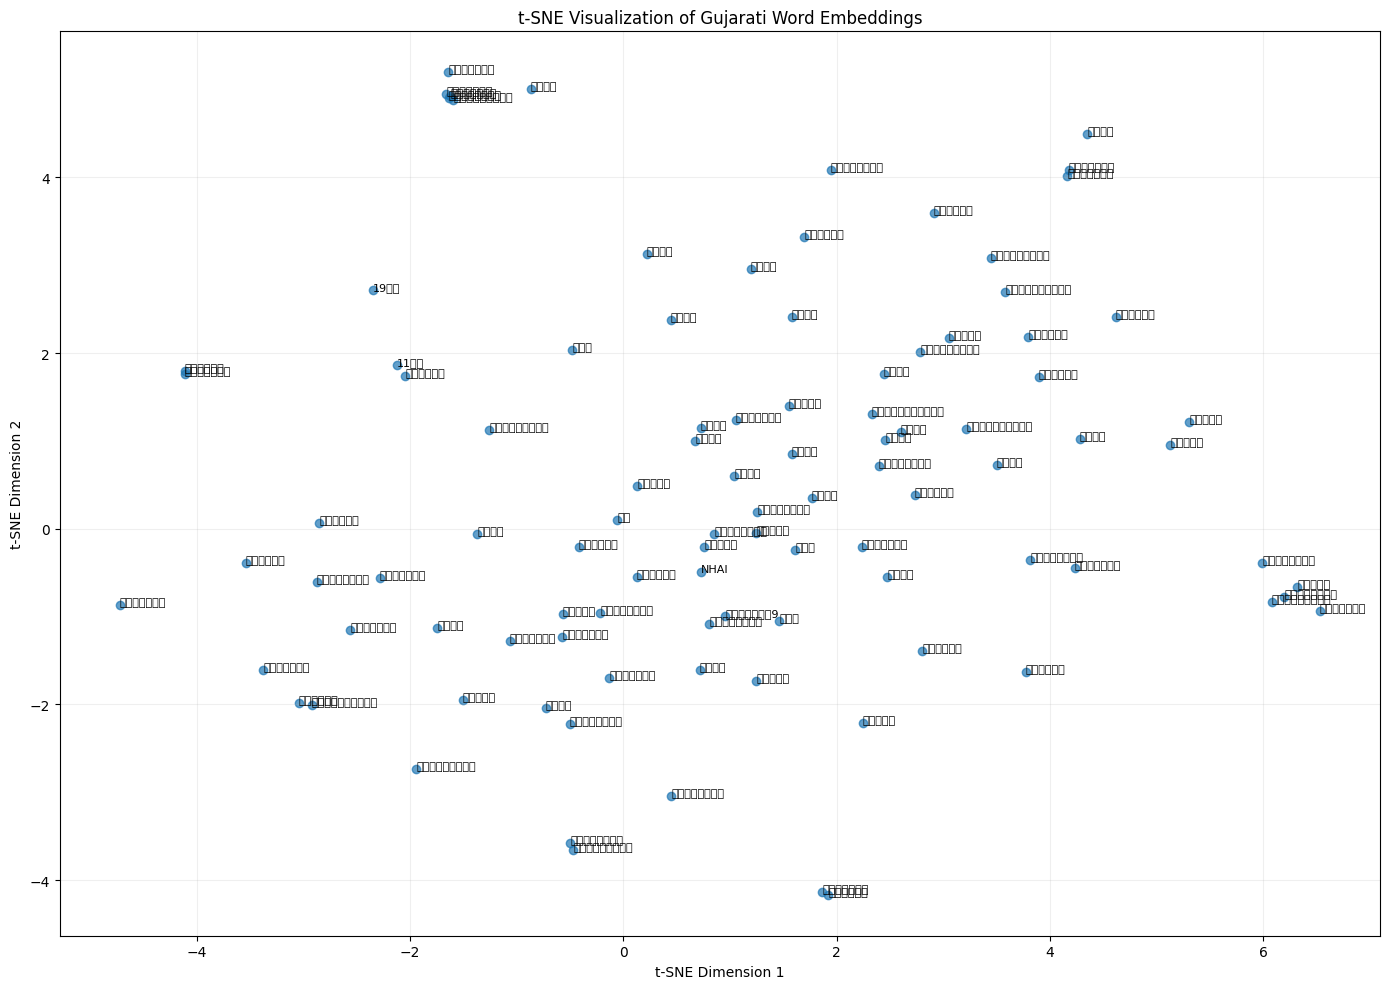

Saved: FOVL_Project/evaluation/tsne_plots/Gujarati_tsne.png
Generating t-SNE for Hindi...


/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2342 (\N{DEVANAGARI LETTER DA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2370 (\N{DEVANAGARI VOWEL SIGN UU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2354 (\N{DEVANAGARI LETTER LA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2381 (\N{DEVANAGARI SIGN VIRAMA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2361 (\N{DEVANAGARI LETTER HA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2375 (\N{DEVANAGARI VOWEL SIGN E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tm

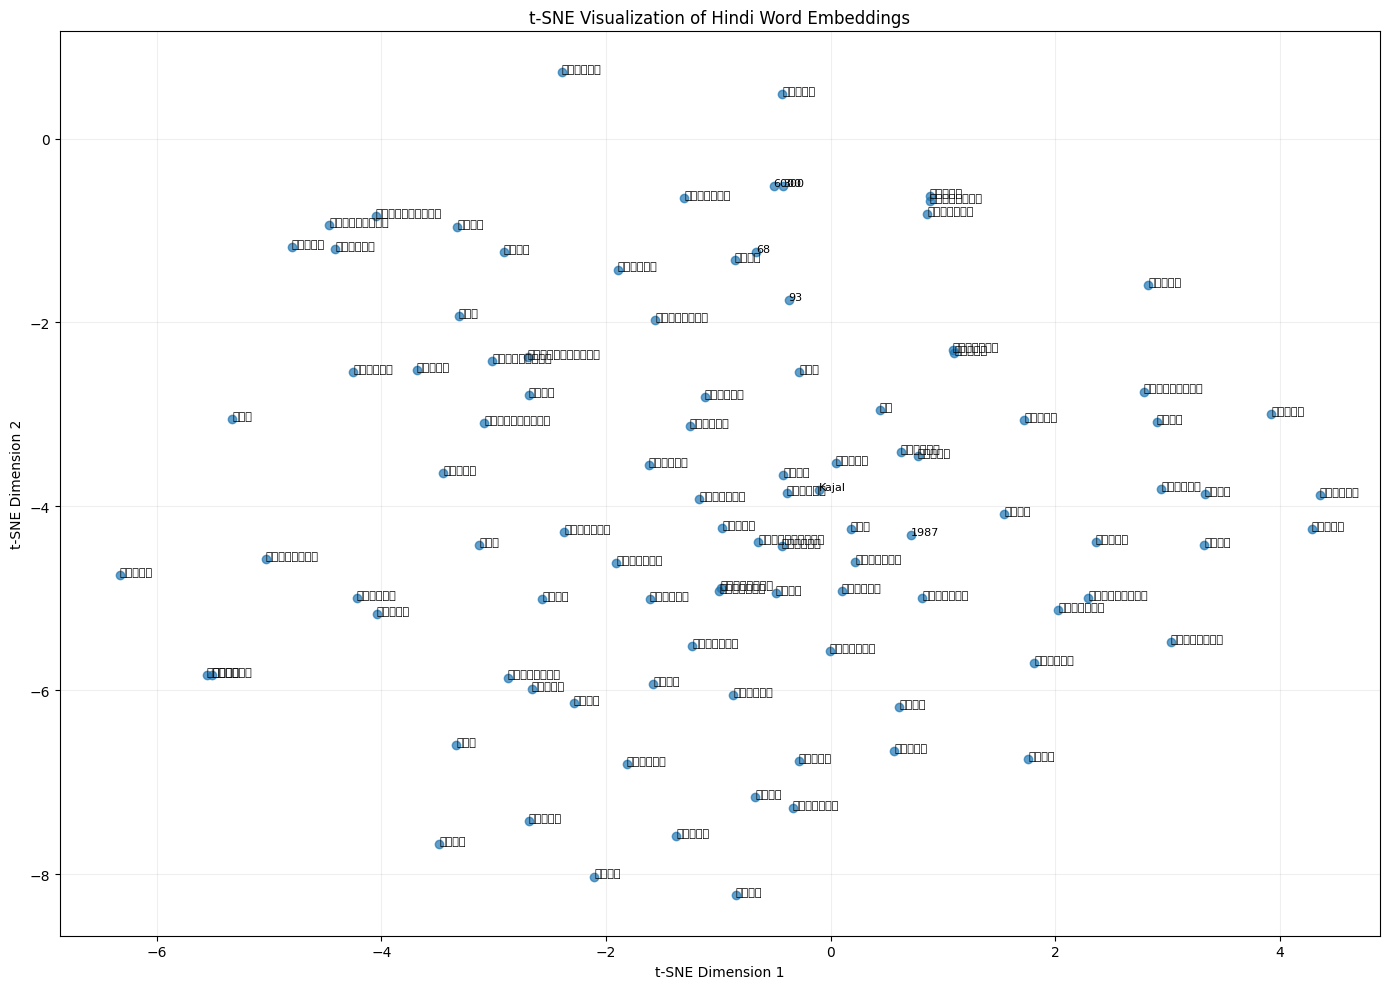

Saved: FOVL_Project/evaluation/tsne_plots/Hindi_tsne.png
Generating t-SNE for Marathi...


/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2340 (\N{DEVANAGARI LETTER TA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2332 (\N{DEVANAGARI LETTER JA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2381 (\N{DEVANAGARI SIGN VIRAMA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2351 (\N{DEVANAGARI LETTER YA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/i

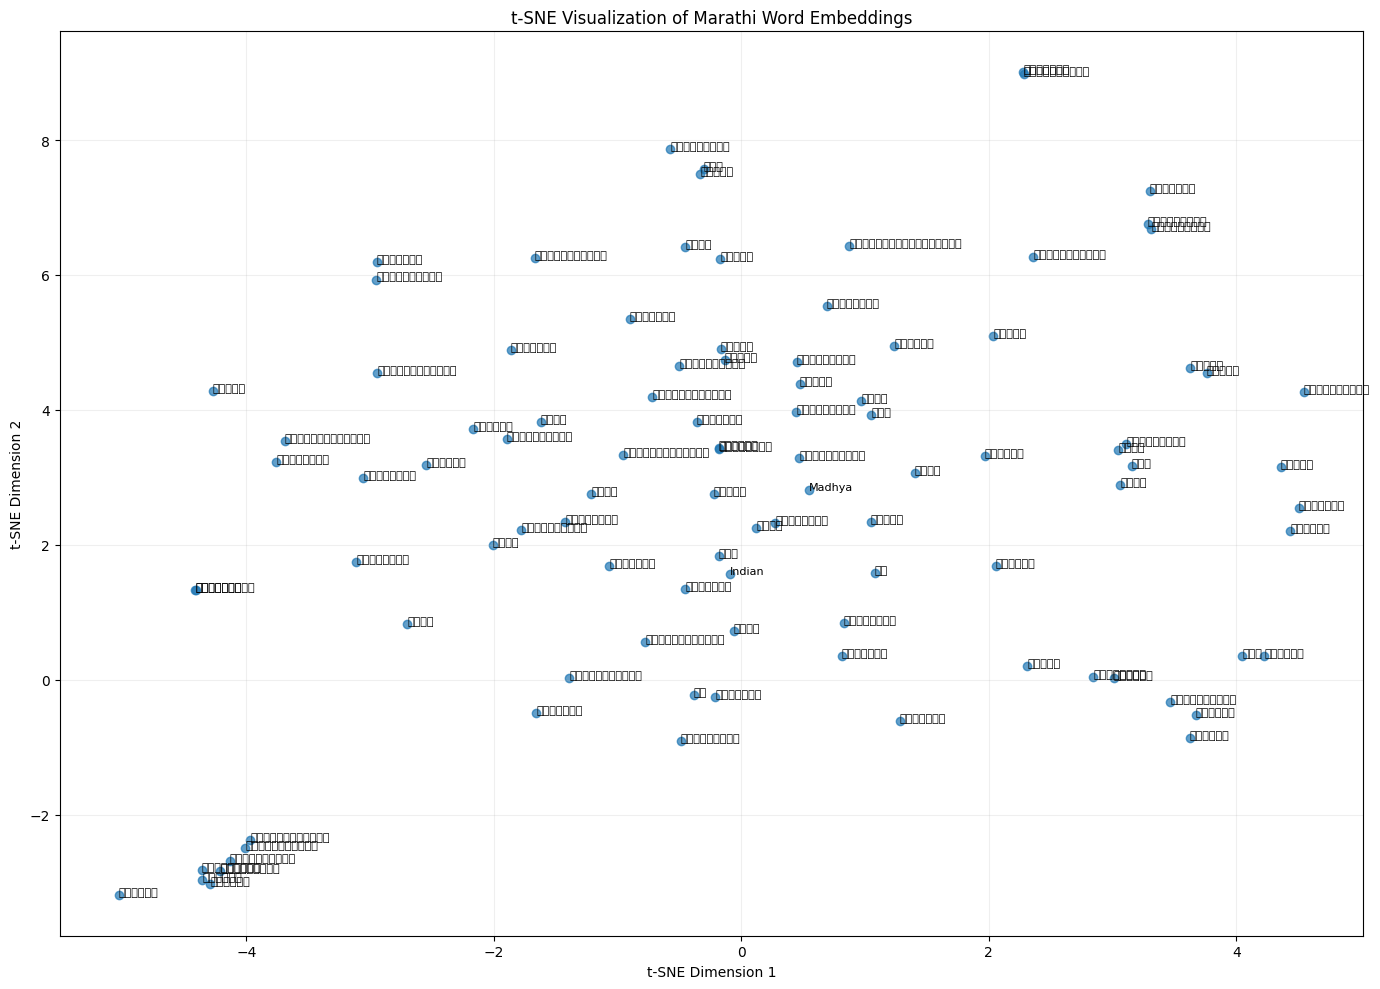

Saved: FOVL_Project/evaluation/tsne_plots/Marathi_tsne.png
Generating t-SNE for Punjabi...


/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2588 (\N{GURMUKHI LETTER JA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Matplotlib currently does not support Gurmukhi natively.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2620 (\N{GURMUKHI SIGN NUKTA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2617 (\N{GURMUKHI LETTER HA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2623 (\N{GURMUKHI VOWEL SIGN I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2608 (\N{GURMUKHI LETTER RA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2616 (\N{GURMUKHI LETTER SA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/246

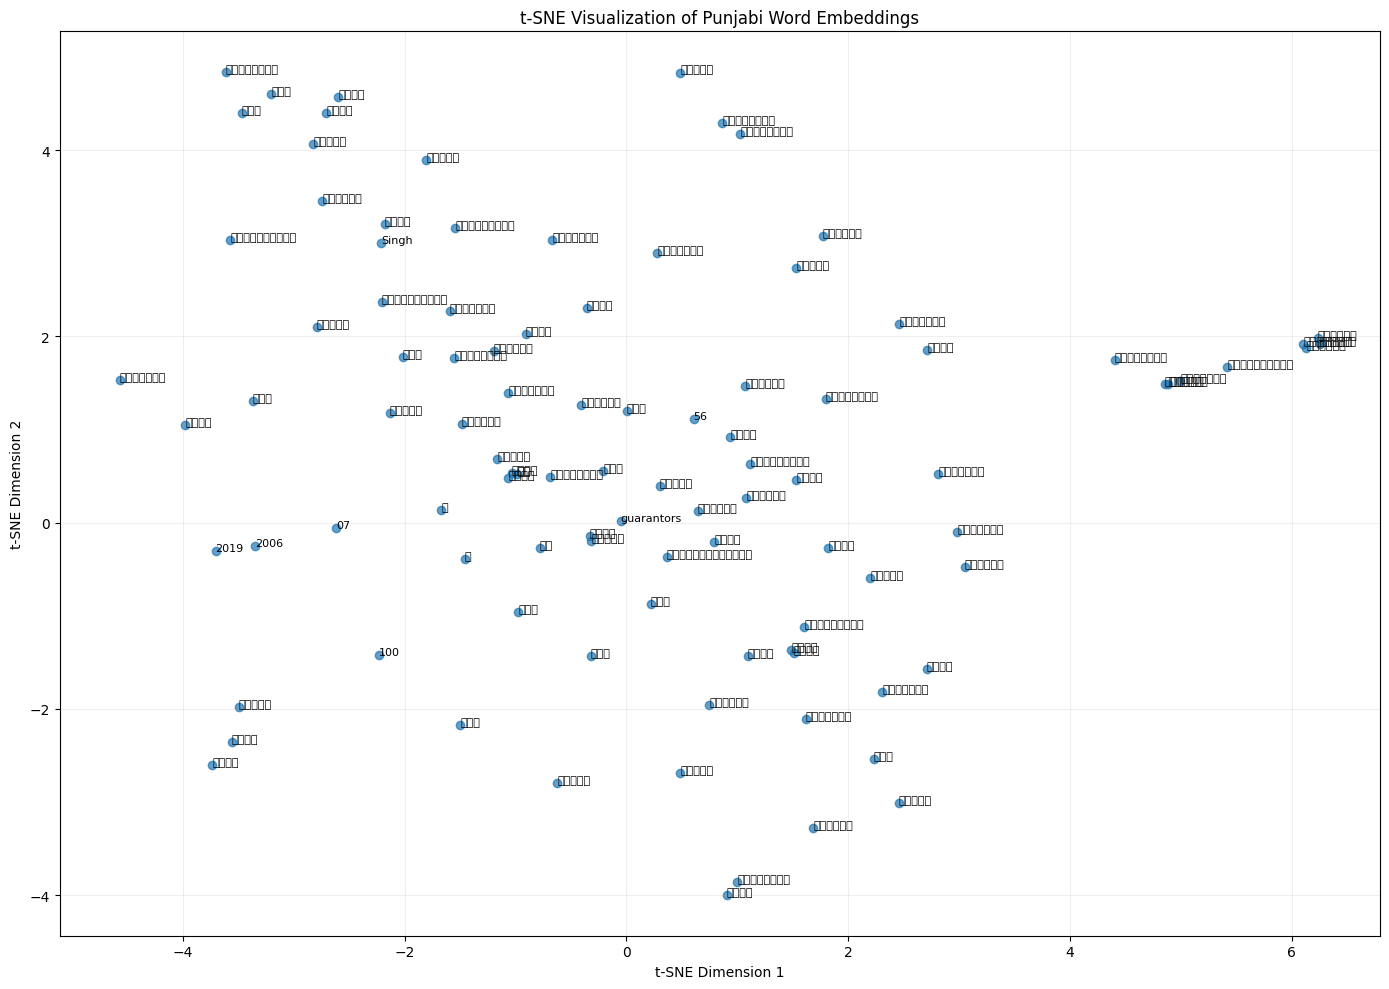

Saved: FOVL_Project/evaluation/tsne_plots/Punjabi_tsne.png
Generating t-SNE for Tamil...


/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2997 (\N{TAMIL LETTER VA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Matplotlib currently does not support Tamil natively.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 3007 (\N{TAMIL VOWEL SIGN I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2972 (\N{TAMIL LETTER JA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2991 (\N{TAMIL LETTER YA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 3006 (\N{TAMIL VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 2990 (\N{TAMIL LETTER MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: Use

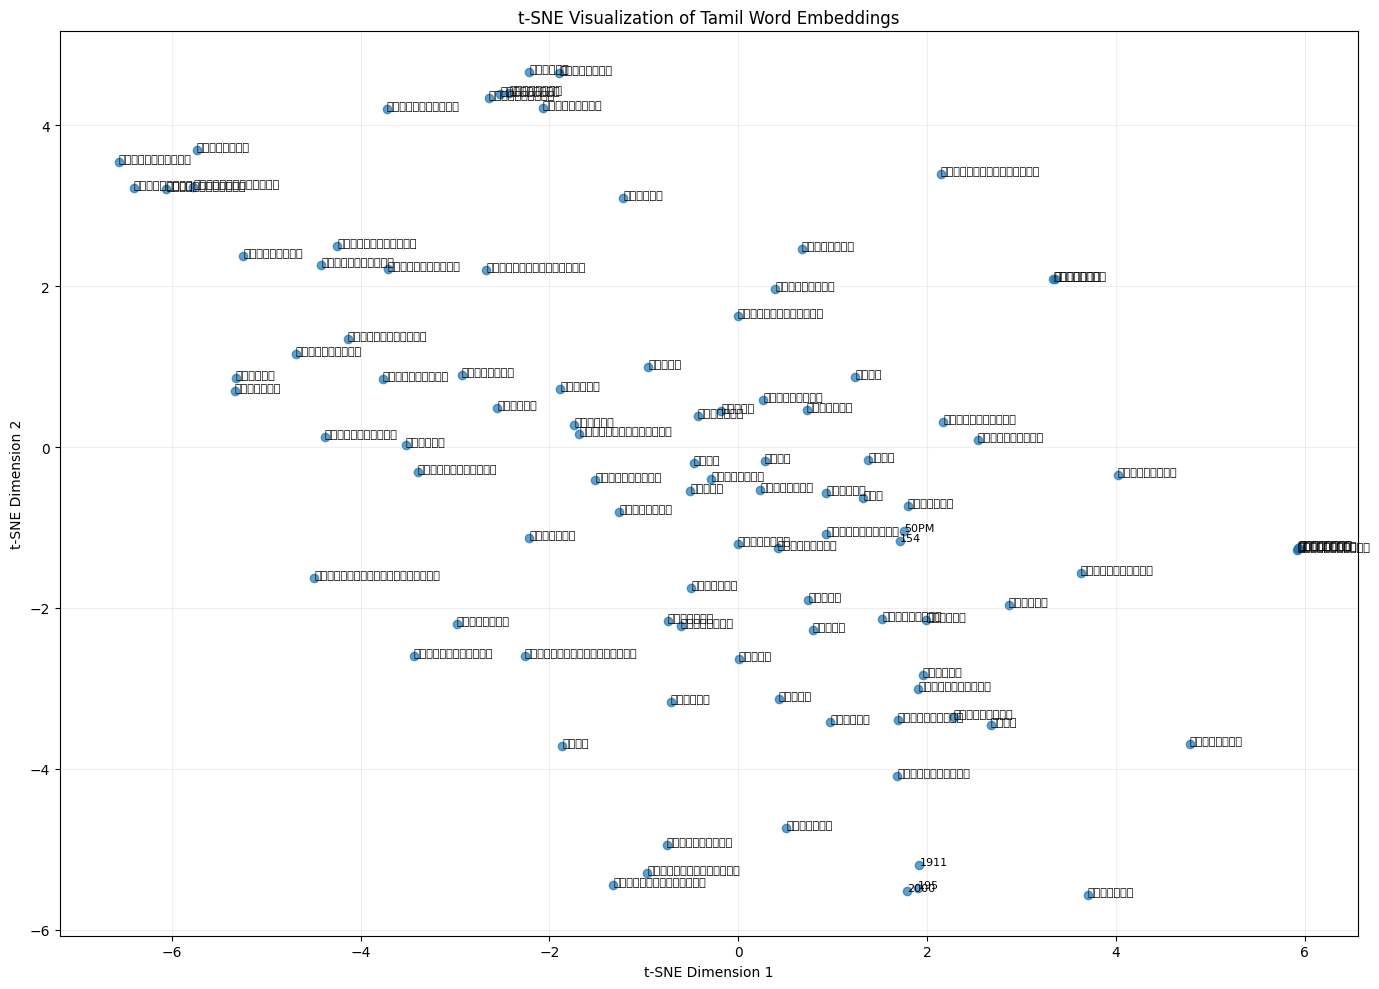

Saved: FOVL_Project/evaluation/tsne_plots/Tamil_tsne.png
Generating t-SNE for Telugu...


/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 3122 (\N{TELUGU LETTER LA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Matplotlib currently does not support Telugu natively.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 3147 (\N{TELUGU VOWEL SIGN OO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 3093 (\N{TELUGU LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 3149 (\N{TELUGU SIGN VIRAMA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 3116 (\N{TELUGU LETTER BA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 3128 (\N{TELUGU LETTER SA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:7

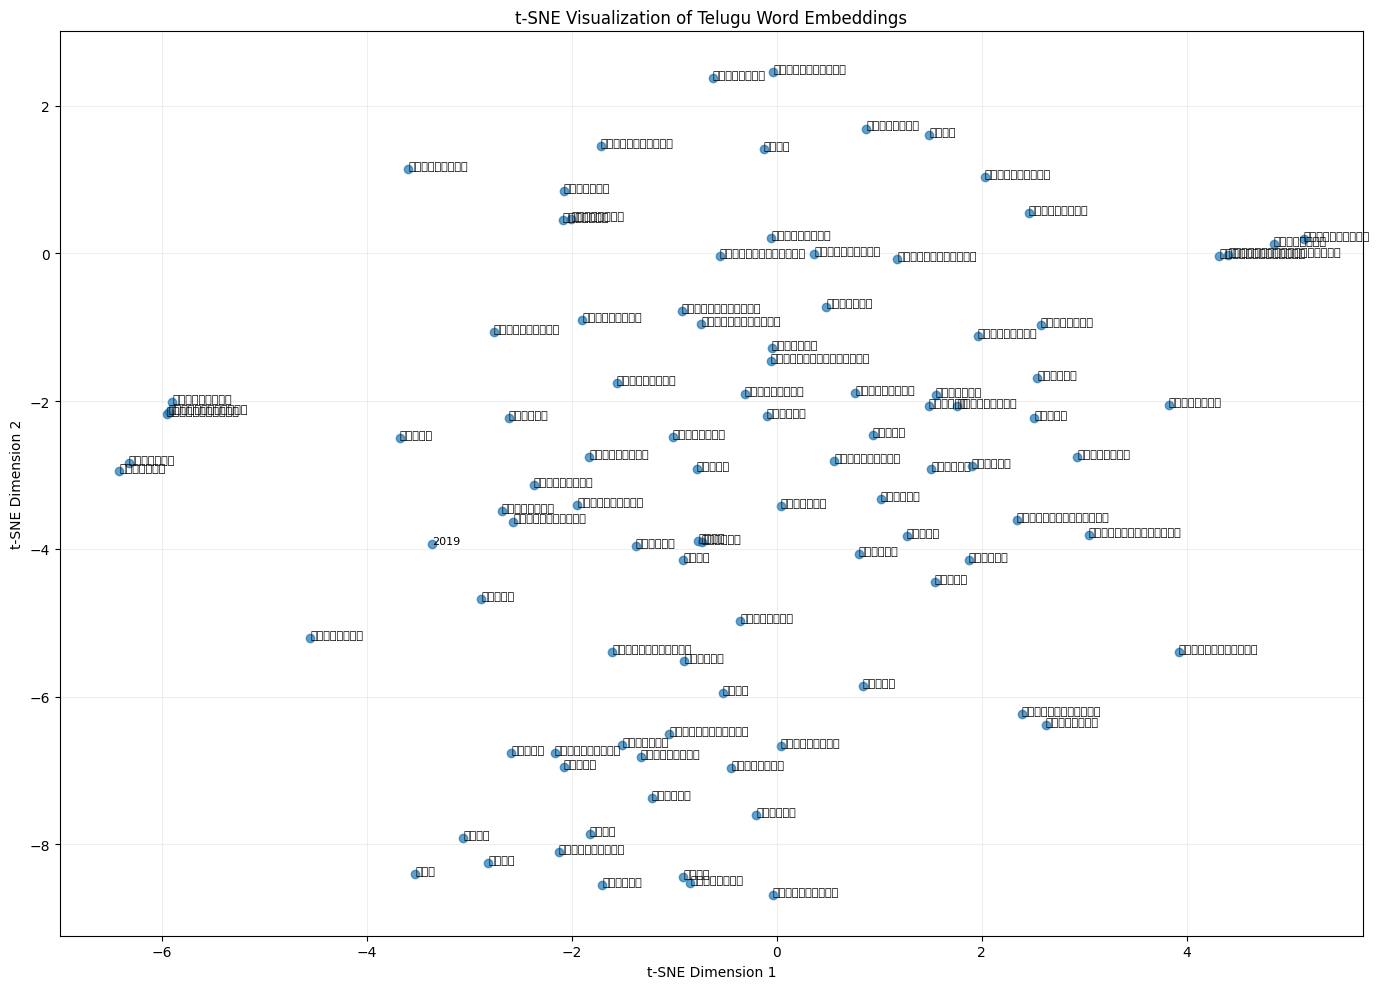

Saved: FOVL_Project/evaluation/tsne_plots/Telugu_tsne.png
Generating t-SNE for Urdu...


/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 1729 (\N{ARABIC LETTER HEH GOAL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Matplotlib currently does not support Arabic natively.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 65018 (\N{ARABIC LIGATURE SALLALLAHOU ALAYHE WASALLAM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:78: UserWarning: Glyph 1746 (\N{ARABIC LETTER YEH BARREE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_675/2465758649.py:85: UserWarning: Glyph 1729 (\N{ARABIC LETTER HEH GOAL}) missing from font(s) DejaVu Sans.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/tmp/ipykernel_675/2465758649.py:85: UserWarning: Matplotlib currently does not support Arabic natively.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/tmp/ipykernel_675/2465758649.py:85: UserWarning: Glyph 65018 (\N{ARABIC LIG

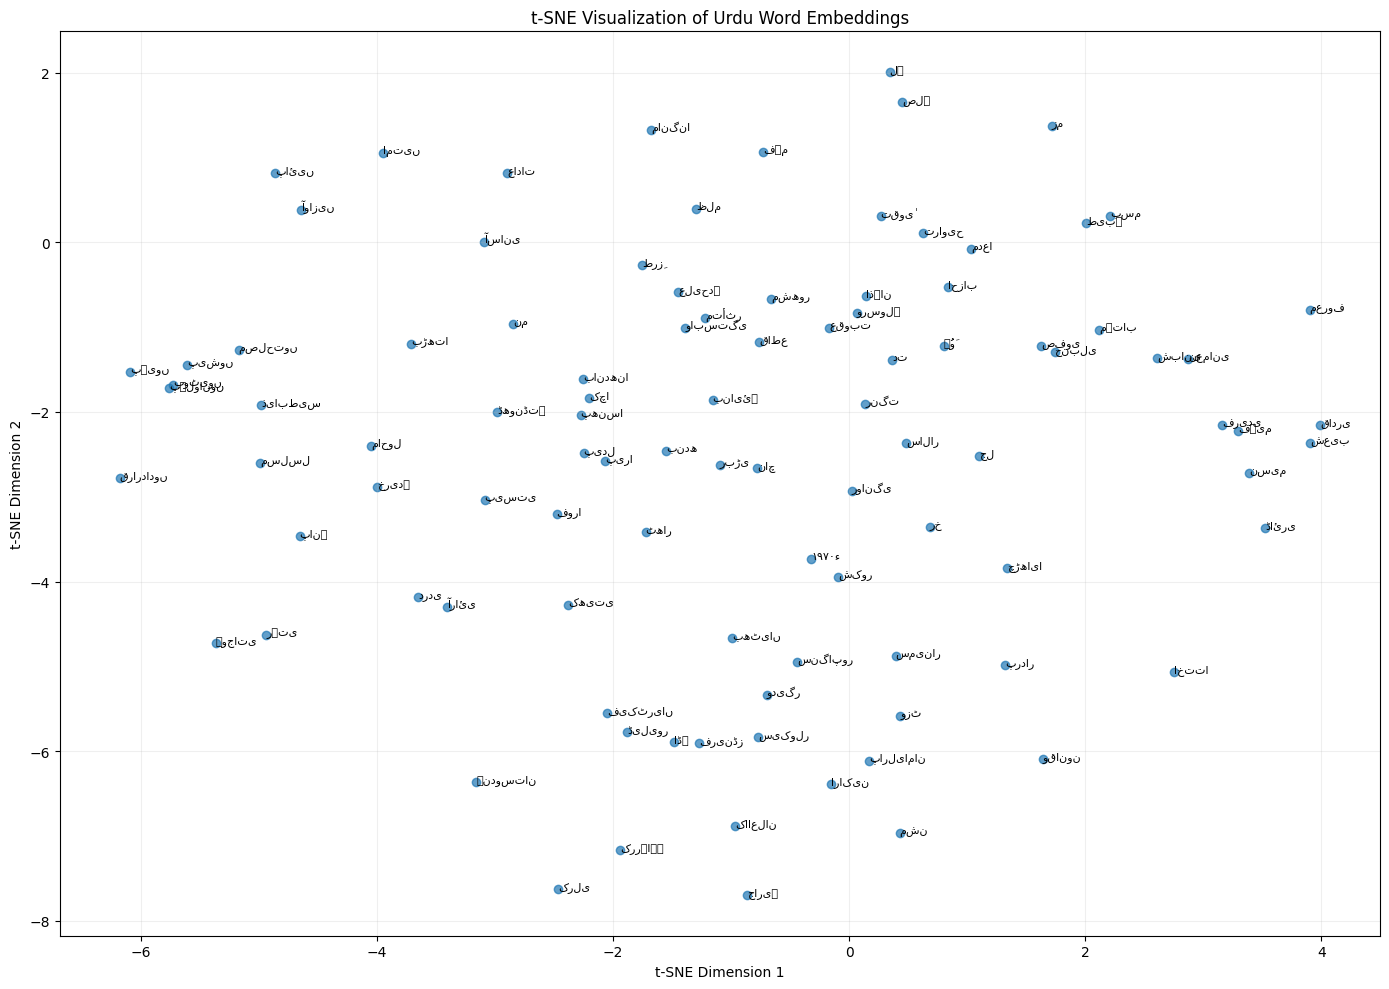

Saved: FOVL_Project/evaluation/tsne_plots/Urdu_tsne.png

All t-SNE visualizations completed!


In [ ]:

import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from gensim.models import FastText

# Languages included in the evaluation benchmark
languages = [
    "Gujarati", "Hindi", "Marathi", "Punjabi",
    "Tamil", "Telugu", "Urdu"
]

# Folder to save t-SNE plots
tsne_dir = "FOVL_Project/evaluation/tsne_plots"
os.makedirs(tsne_dir, exist_ok=True)

for language in languages:

    print(f"Generating t-SNE for {language}...")

    # Load trained FastText model
    model_path = (
        "FOVL_Project/models/"
        + language.replace(" ", "_")
        + "_fasttext.model"
    )

    model = FastText.load(model_path)

    # Select 100 words from the model vocabulary
    vocabulary = model.wv.index_to_key

    if len(vocabulary) < 100:
        print(f"Not enough words for {language}. Skipping.")
        continue

    rng = np.random.default_rng(42)
    selected_words = rng.choice(
        vocabulary, size=100, replace=False
    ).tolist()

    # Extract 300-dimensional word vectors
    vectors = np.array([
        model.wv[word] for word in selected_words
    ])

    # Reduce dimensions from 300 to 2
    tsne = TSNE(
        n_components=2,
        perplexity=30,
        random_state=42,
        init="pca",
        learning_rate="auto"
    )

    reduced_vectors = tsne.fit_transform(vectors)

    # Plot the results
    plt.figure(figsize=(14, 10))

    plt.scatter(
        reduced_vectors[:, 0],
        reduced_vectors[:, 1],
        alpha=0.7
    )

    for i, word in enumerate(selected_words):
        plt.annotate(
            word,
            (reduced_vectors[i, 0], reduced_vectors[i, 1]),
            fontsize=8
        )

    plt.title(f"t-SNE Visualization of {language} Word Embeddings")
    plt.xlabel("t-SNE Dimension 1")
    plt.ylabel("t-SNE Dimension 2")
    plt.grid(alpha=0.2)
    plt.tight_layout()

    # Save each plot
    save_path = os.path.join(
        tsne_dir, language + "_tsne.png"
    )

    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print(f"Saved: {save_path}")

print("\nAll t-SNE visualizations completed!")


In [ ]:

!apt-get -qq update
!apt-get -qq install -y fonts-noto-core fonts-noto-extra

!pip -q install arabic-reshaper python-bidi


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
W: Failed to fetch https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu/dists/noble/InRelease  Could not connect to ppa.launchpadcontent.net:443 (185.125.189.187), connection timed out Could not connect to ppa.launchpadcontent.net:443 (185.125.189.188), connection timed out Could not connect to ppa.launchpadcontent.net:443 (185.125.189.186), connection timed out
W: Failed to fetch http://security.ubuntu.com/ubuntu/dists/noble-security/InRelease  Could not resolve 'security.ubuntu.com'
W: Some index files failed to download. They have been ignored, or old ones used instead.
Selecting previously unselected package fonts-noto-mono.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../fonts-noto-mono_20201225-2_all.deb ...
Unpacking fonts-noto-mono (20201225-

In [ ]:

import matplotlib.font_manager as fm

# Refresh Matplotlib's font cache
fm._load_fontmanager(try_read_cache=False)

font_names = [
    "Noto Sans Gujarati",
    "Noto Sans Devanagari",
    "Noto Sans Gurmukhi",
    "Noto Sans Tamil",
    "Noto Sans Telugu",
    "Noto Sans Arabic"
]

for name in font_names:
    try:
        print(name, ":", fm.findfont(name))
    except Exception as e:
        print(name, "not found")


Noto Sans Gujarati : /usr/local/lib/python3.13/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf
Noto Sans Devanagari : /usr/local/lib/python3.13/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf
Noto Sans Gurmukhi : /usr/local/lib/python3.13/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf
Noto Sans Tamil : /usr/local/lib/python3.13/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf
Noto Sans Telugu : /usr/local/lib/python3.13/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf
Noto Sans Arabic : /usr/local/lib/python3.13/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf


In [ ]:
font_mapping = {
    "Gujarati": "Noto Sans Gujarati",
    "Hindi": "Noto Sans Devanagari",
    "Marathi": "Noto Sans Devanagari",
    "Punjabi": "Noto Sans Gurmukhi",
    "Tamil": "Noto Sans Tamil",
    "Telugu": "Noto Sans Telugu",
    "Urdu": "Noto Sans Arabic"
}

In [ ]:
import matplotlib.font_manager as fm
import subprocess

# Refresh Matplotlib font cache
fm._load_fontmanager(try_read_cache=False)

# Check fonts available for Indic scripts
result = subprocess.run(
    ["fc-list", ":lang=gu,hi,pa,ta,te,ur", "family"],
    capture_output=True,
    text=True
)

print(result.stdout)

In [ ]:
font_names = [
    "Noto Sans Gujarati",
    "Noto Sans Devanagari",
    "Noto Sans Gurmukhi",
    "Noto Sans Tamil",
    "Noto Sans Telugu",
    "Noto Naskh Arabic"
]

for name in font_names:
    print(name, ":", fm.findfont(name, fallback_to_default=False)
          if any(name.lower() in f.name.lower()
                 for f in fm.fontManager.ttflist)
          else "NOT FOUND")

Noto Sans Gujarati : NOT FOUND
Noto Sans Devanagari : NOT FOUND
Noto Sans Gurmukhi : NOT FOUND
Noto Sans Tamil : NOT FOUND
Noto Sans Telugu : NOT FOUND
Noto Naskh Arabic : NOT FOUND


In [ ]:
!apt-get update -qq
!apt-get install -y fonts-noto-core fonts-noto-extra fonts-noto-ui-core

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
W: Failed to fetch https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu/dists/noble/InRelease  Could not connect to ppa.launchpadcontent.net:443 (185.125.189.188), connection timed out Could not connect to ppa.launchpadcontent.net:443 (185.125.189.186), connection timed out Could not connect to ppa.launchpadcontent.net:443 (185.125.189.187), connection timed out
W: Some index files failed to download. They have been ignored, or old ones used instead.
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-noto-core is already the newest version (20201225-2).
fonts-noto-extra is already the newest version (20201225-2).
The following NEW packages will be installed:
  fonts-noto-ui-core
0 upgraded, 1 newly installed, 0 to remove and 40 not upgraded.
Need 

In [ ]:
import matplotlib.font_manager as fm
import subprocess

# Refresh font cache
!fc-cache -f -v

# Refresh Matplotlib font manager
fm._load_fontmanager(try_read_cache=False)

# Display installed Noto fonts
for font in fm.fontManager.ttflist:
    if "noto" in font.name.lower():
        print(font.name, ":", font.fname)

Font directories:
	/root/.local/share/fonts
	/usr/local/share/fonts
	/usr/share/fonts
	/root/.fonts
	/usr/share/fonts/truetype
	/usr/share/fonts/truetype/humor-sans
	/usr/share/fonts/truetype/liberation
	/usr/share/fonts/truetype/noto
/root/.local/share/fonts: skipping, no such directory
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/truetype/liberation: caching, new cache contents: 12 fonts, 0 dirs
/usr/share/fonts/truetype/noto: caching, new cache contents: 1847 fonts, 0 dirs
/root/.fonts: skipping, no such directory
/usr/share/fonts/truetype: skipping, looped directory detected
/usr/share/fonts/truetype/humor-sans: skipping, looped directory detected
/usr/share/fonts/truetype/liberation: skipping, looped directory detected
/usr/sh

In [ ]:
import subprocess

result = subprocess.run(
    ["fc-list", ":lang=gu,hi,pa,ta,te,ur", "family"],
    capture_output=True,
    text=True
)

font_families = sorted(set(result.stdout.splitlines()))

for family in font_families:
    print(family)

In [ ]:
import matplotlib.font_manager as fm

fm._load_fontmanager(try_read_cache=False)

for font in fm.fontManager.ttflist:
    if "noto" in font.name.lower():
        if any(script in font.name.lower() for script in
               ["gujarati", "devanagari", "gurmukhi",
                "tamil", "telugu", "arabic"]):
            print(font.name, ":", font.fname)

In [ ]:
import os

font_dir = "/usr/share/fonts/truetype/noto"

print("Directory exists:", os.path.exists(font_dir))

if os.path.exists(font_dir):
    files = os.listdir(font_dir)
    print("Number of files:", len(files))
    print("First 20 files:", files[:20])

Directory exists: True
Number of files: 1847
First 20 files: ['NotoSerifTamil-ExtraCondensed.ttf', 'NotoSansMyanmar-ExtraBold.ttf', 'NotoSansMalayalam-CondensedMedium.ttf', 'NotoSansEthiopic-ExtraCondensedMedium.ttf', 'NotoSansMeeteiMayek-Black.ttf', 'NotoSerif-SemiCondensedExtraBoldItalic.ttf', 'NotoSansHebrew-SemiCondensedBold.ttf', 'NotoSansMyanmar-CondensedThin.ttf', 'NotoSerifDisplay-CondensedBold.ttf', 'NotoSansDevanagari-ExtraCondensedExtraLight.ttf', 'NotoSansKannada-SemiCondensedBold.ttf', 'NotoSerifSinhala-CondensedBlack.ttf', 'NotoSansMyanmar-ExtraCondensedBold.ttf', 'NotoSansLao-CondensedExtraLight.ttf', 'NotoSansThai-SemiCondensedBold.ttf', 'NotoSansArabic-Light.ttf', 'NotoSansHebrew-Regular.ttf', 'NotoSerif-ExtraCondensedLight.ttf', 'NotoSansMono-Thin.ttf', 'NotoSans-ExtraCondensedSemiBoldItalic.ttf']


In [ ]:
import os

font_dir = "/usr/share/fonts/truetype/noto"

patterns = [
    "NotoSansGujarati-Regular.ttf",
    "NotoSansDevanagari-Regular.ttf",
    "NotoSansGurmukhi-Regular.ttf",
    "NotoSansTamil-Regular.ttf",
    "NotoSansTelugu-Regular.ttf",
    "NotoNaskhArabic-Regular.ttf"
]

for filename in patterns:
    path = os.path.join(font_dir, filename)
    print(filename, "FOUND" if os.path.exists(path) else "NOT FOUND")

NotoSansGujarati-Regular.ttf FOUND
NotoSansDevanagari-Regular.ttf FOUND
NotoSansGurmukhi-Regular.ttf FOUND
NotoSansTamil-Regular.ttf FOUND
NotoSansTelugu-Regular.ttf FOUND
NotoNaskhArabic-Regular.ttf FOUND


In [ ]:
!pip -q install arabic-reshaper python-bidi

1. Starting Gujarati test
2. Gujarati model loaded
3. Vectors shape: (100, 300)
4. t-SNE completed: (100, 2)


/tmp/ipykernel_675/3032749433.py:44: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Gujarati.
  plt.tight_layout()
/tmp/ipykernel_675/3032749433.py:44: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Gujarati.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Gujarati.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Gujarati.
  fig.canvas.print_figure(bytes_io, **kw)


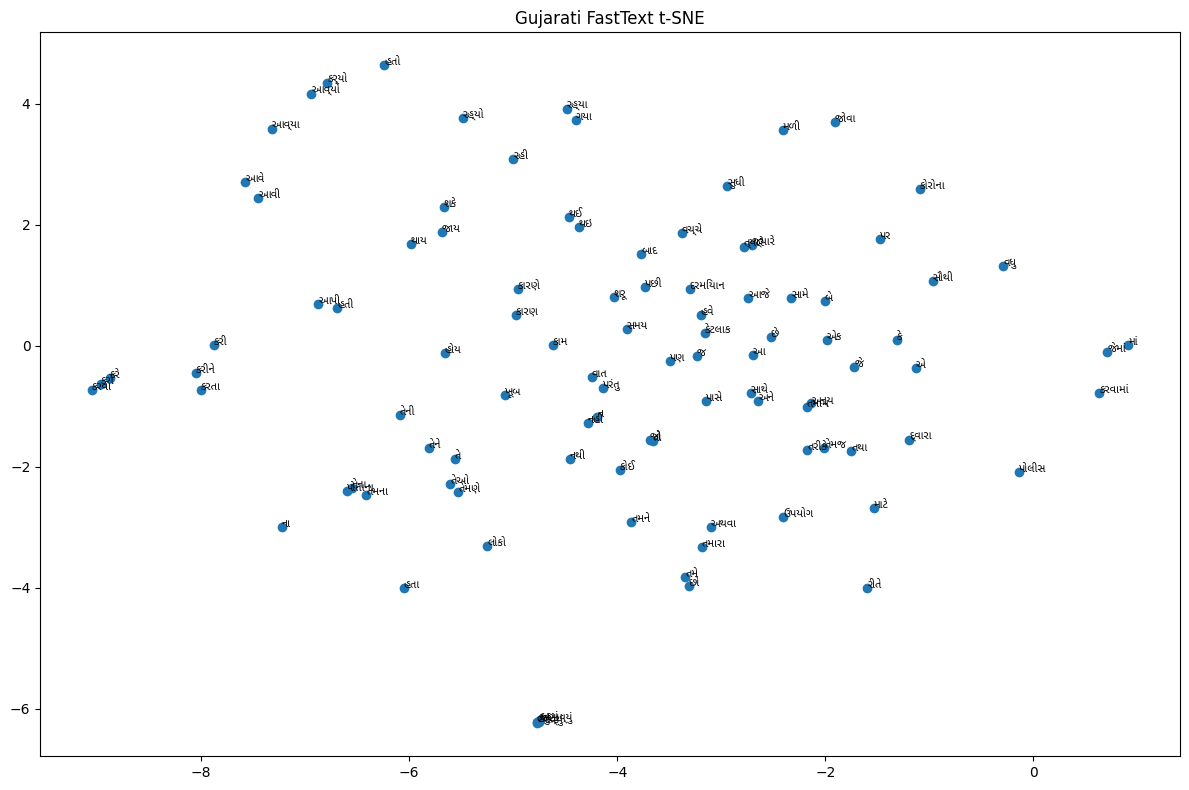

5. Gujarati test completed!


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from gensim.models import FastText
from sklearn.manifold import TSNE
import numpy as np

print("1. Starting Gujarati test")

model = FastText.load(
    "FOVL_Project/models/Gujarati_fasttext.model"
)
print("2. Gujarati model loaded")

words = model.wv.index_to_key[:100]
vectors = np.array([model.wv[word] for word in words])
print("3. Vectors shape:", vectors.shape)

tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    init="pca",
    learning_rate="auto"
)

reduced = tsne.fit_transform(vectors)
print("4. t-SNE completed:", reduced.shape)

font_path = "/usr/share/fonts/truetype/noto/NotoSansGujarati-Regular.ttf"
font_prop = fm.FontProperties(fname=font_path)

plt.figure(figsize=(12, 8))
plt.scatter(reduced[:, 0], reduced[:, 1])

for i, word in enumerate(words):
    plt.annotate(
        word,
        (reduced[i, 0], reduced[i, 1]),
        fontproperties=font_prop,
        fontsize=8
    )

plt.title("Gujarati FastText t-SNE")
plt.tight_layout()
plt.show()

print("5. Gujarati test completed!")


Processing: Gujarati


/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Gujarati.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Gujarati.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 78 (N) missing from font(s) Noto Sans Gujarati.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 72 (H) missing from font(s) Noto Sans Gujarati.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 65 (A) missing from font(s) Noto Sans Gujarati.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 73 (I) missing from font(s) Noto Sans Gujarati.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:104: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Gujarati.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/tmp/ipykernel_675/309947929.py:104: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans

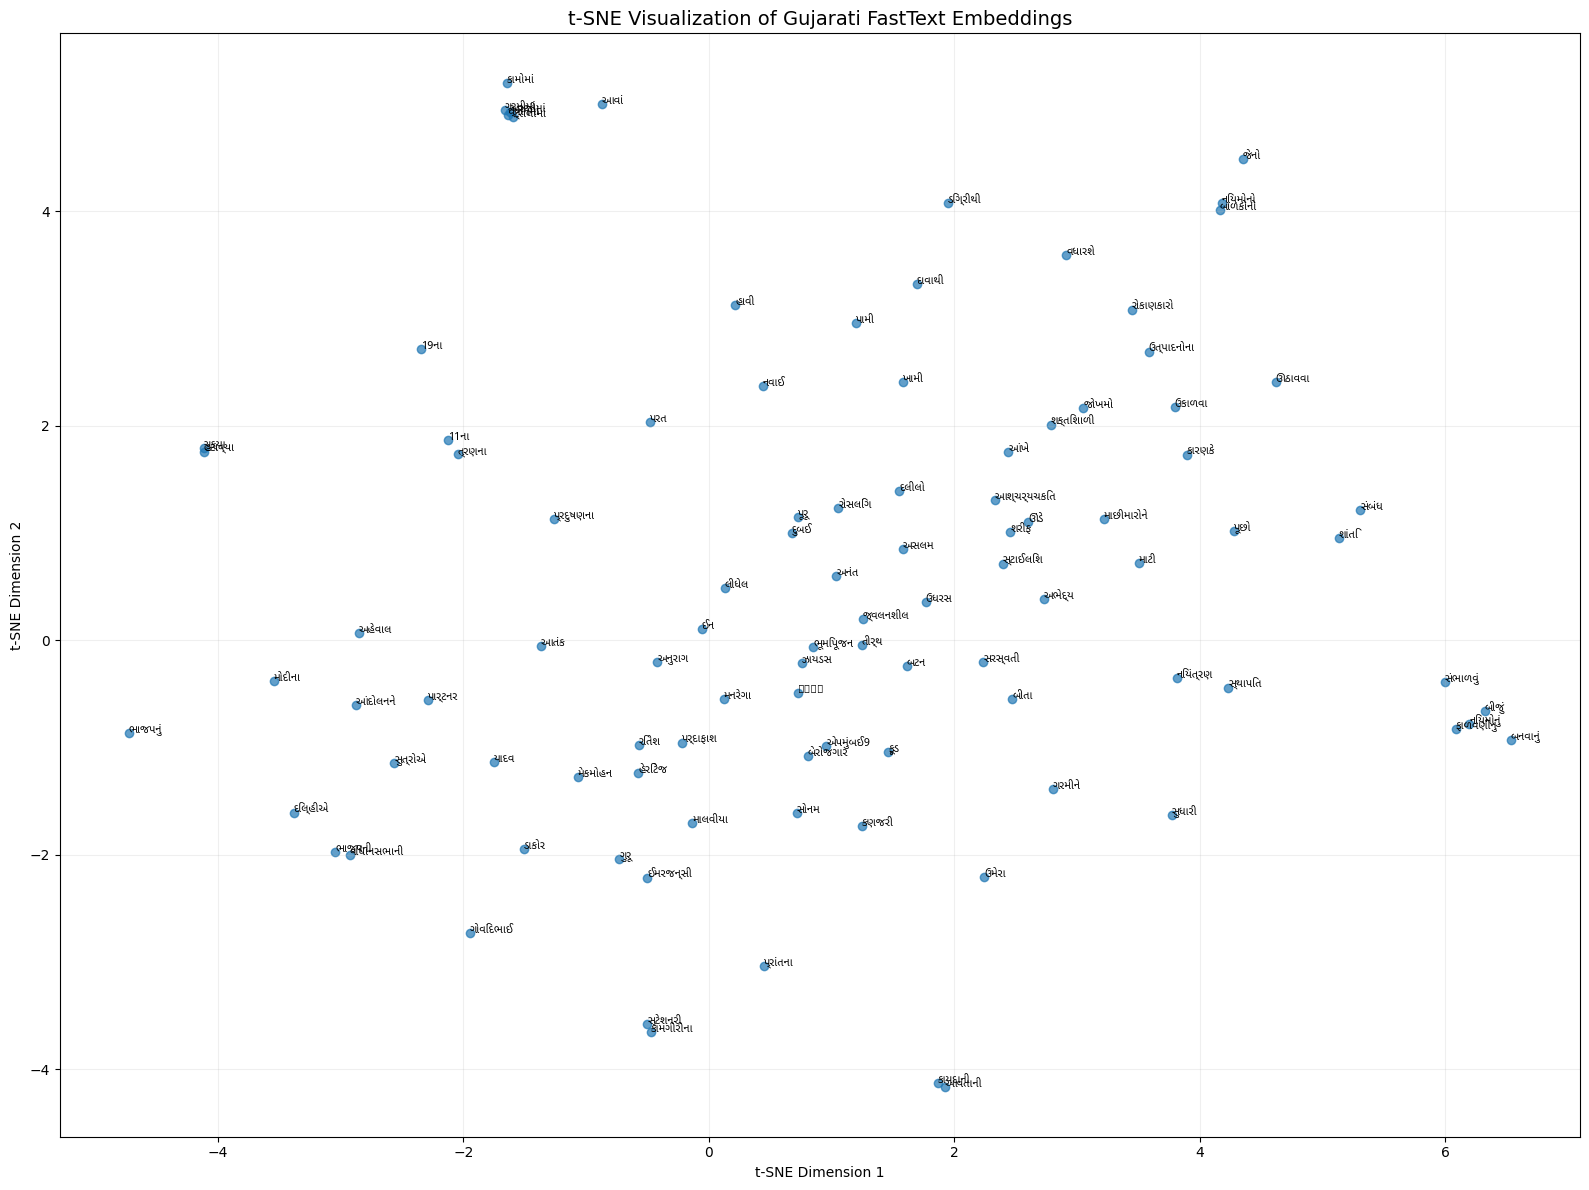

Saved: FOVL_Project/evaluation/tsne_plots/Gujarati_tsne.png

Processing: Hindi


/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Devanagari.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Devanagari.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 75 (K) missing from font(s) Noto Sans Devanagari.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 97 (a) missing from font(s) Noto Sans Devanagari.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 106 (j) missing from font(s) Noto Sans Devanagari.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:104: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Devanagari.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/tmp/ipykernel_675/309947929.py:104: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Devanagari.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/tmp/ipykernel_675/309947929.py:104: UserWa

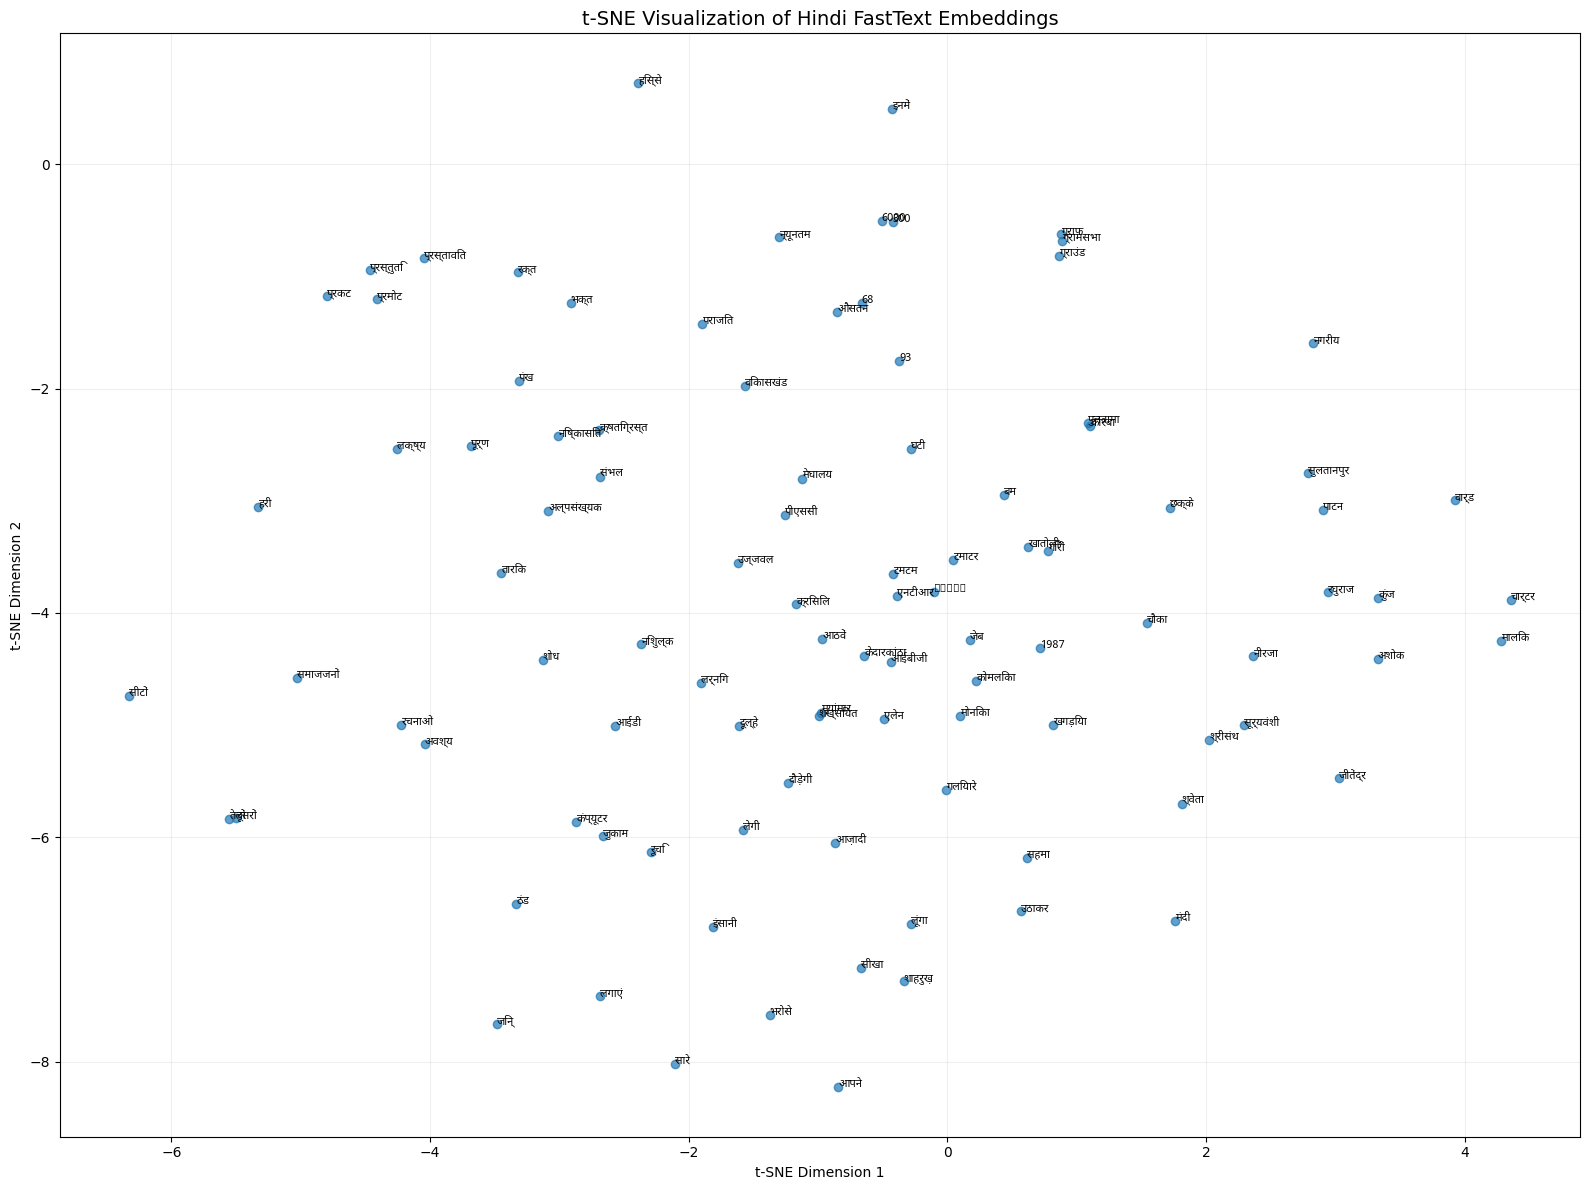

Saved: FOVL_Project/evaluation/tsne_plots/Hindi_tsne.png

Processing: Marathi


/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Devanagari.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Devanagari.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 73 (I) missing from font(s) Noto Sans Devanagari.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 110 (n) missing from font(s) Noto Sans Devanagari.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 100 (d) missing from font(s) Noto Sans Devanagari.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 105 (i) missing from font(s) Noto Sans Devanagari.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 97 (a) missing from font(s) Noto Sans Devanagari.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 77 (M) missing from font(s) Noto Sans Devanagari.
  plt.ti

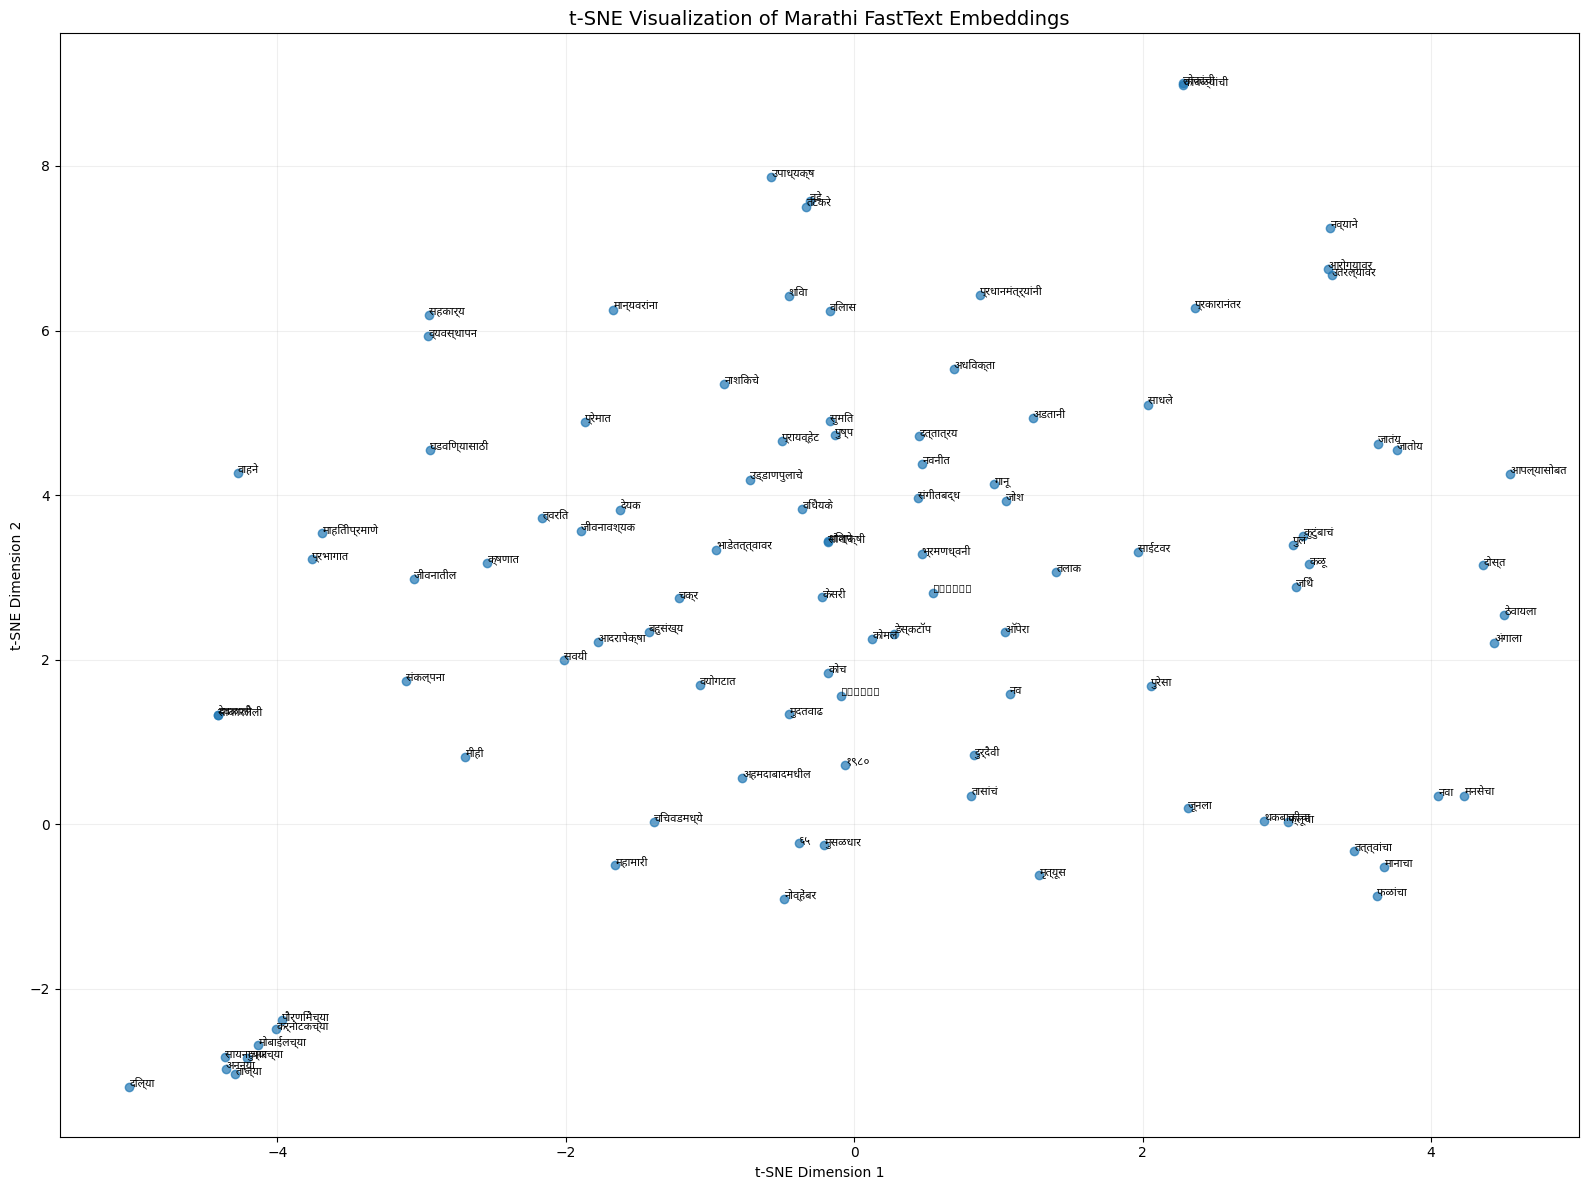

Saved: FOVL_Project/evaluation/tsne_plots/Marathi_tsne.png

Processing: Punjabi


/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Gurmukhi.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Gurmukhi.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 103 (g) missing from font(s) Noto Sans Gurmukhi.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 117 (u) missing from font(s) Noto Sans Gurmukhi.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 97 (a) missing from font(s) Noto Sans Gurmukhi.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 114 (r) missing from font(s) Noto Sans Gurmukhi.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 110 (n) missing from font(s) Noto Sans Gurmukhi.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 116 (t) missing from font(s) Noto Sans Gurmukhi.
  plt.tight_layout()
/

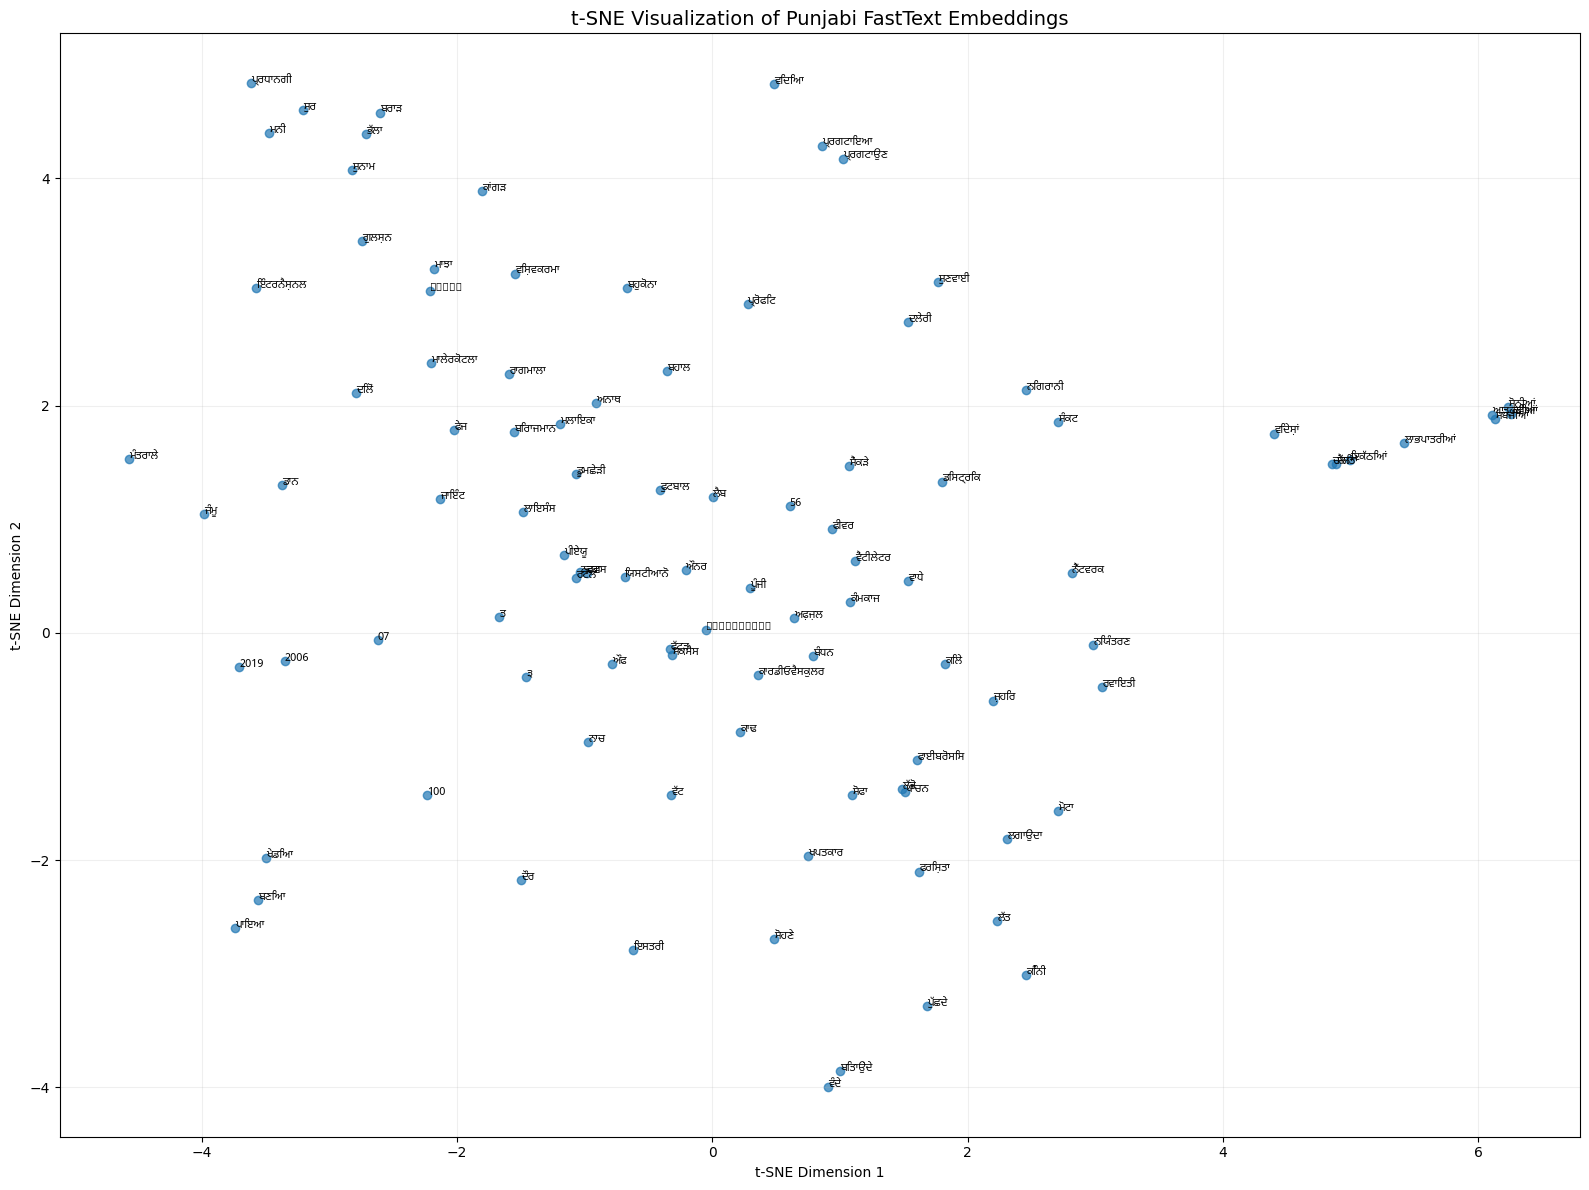

Saved: FOVL_Project/evaluation/tsne_plots/Punjabi_tsne.png

Processing: Tamil


/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Tamil.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Tamil.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 80 (P) missing from font(s) Noto Sans Tamil.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 77 (M) missing from font(s) Noto Sans Tamil.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:104: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Tamil.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/tmp/ipykernel_675/309947929.py:104: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Tamil.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/tmp/ipykernel_675/309947929.py:104: UserWarning: Glyph 80 (P) missing from font(s) Noto Sans Tamil.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/tmp/ipykernel_675/309947929.py:104: UserWar

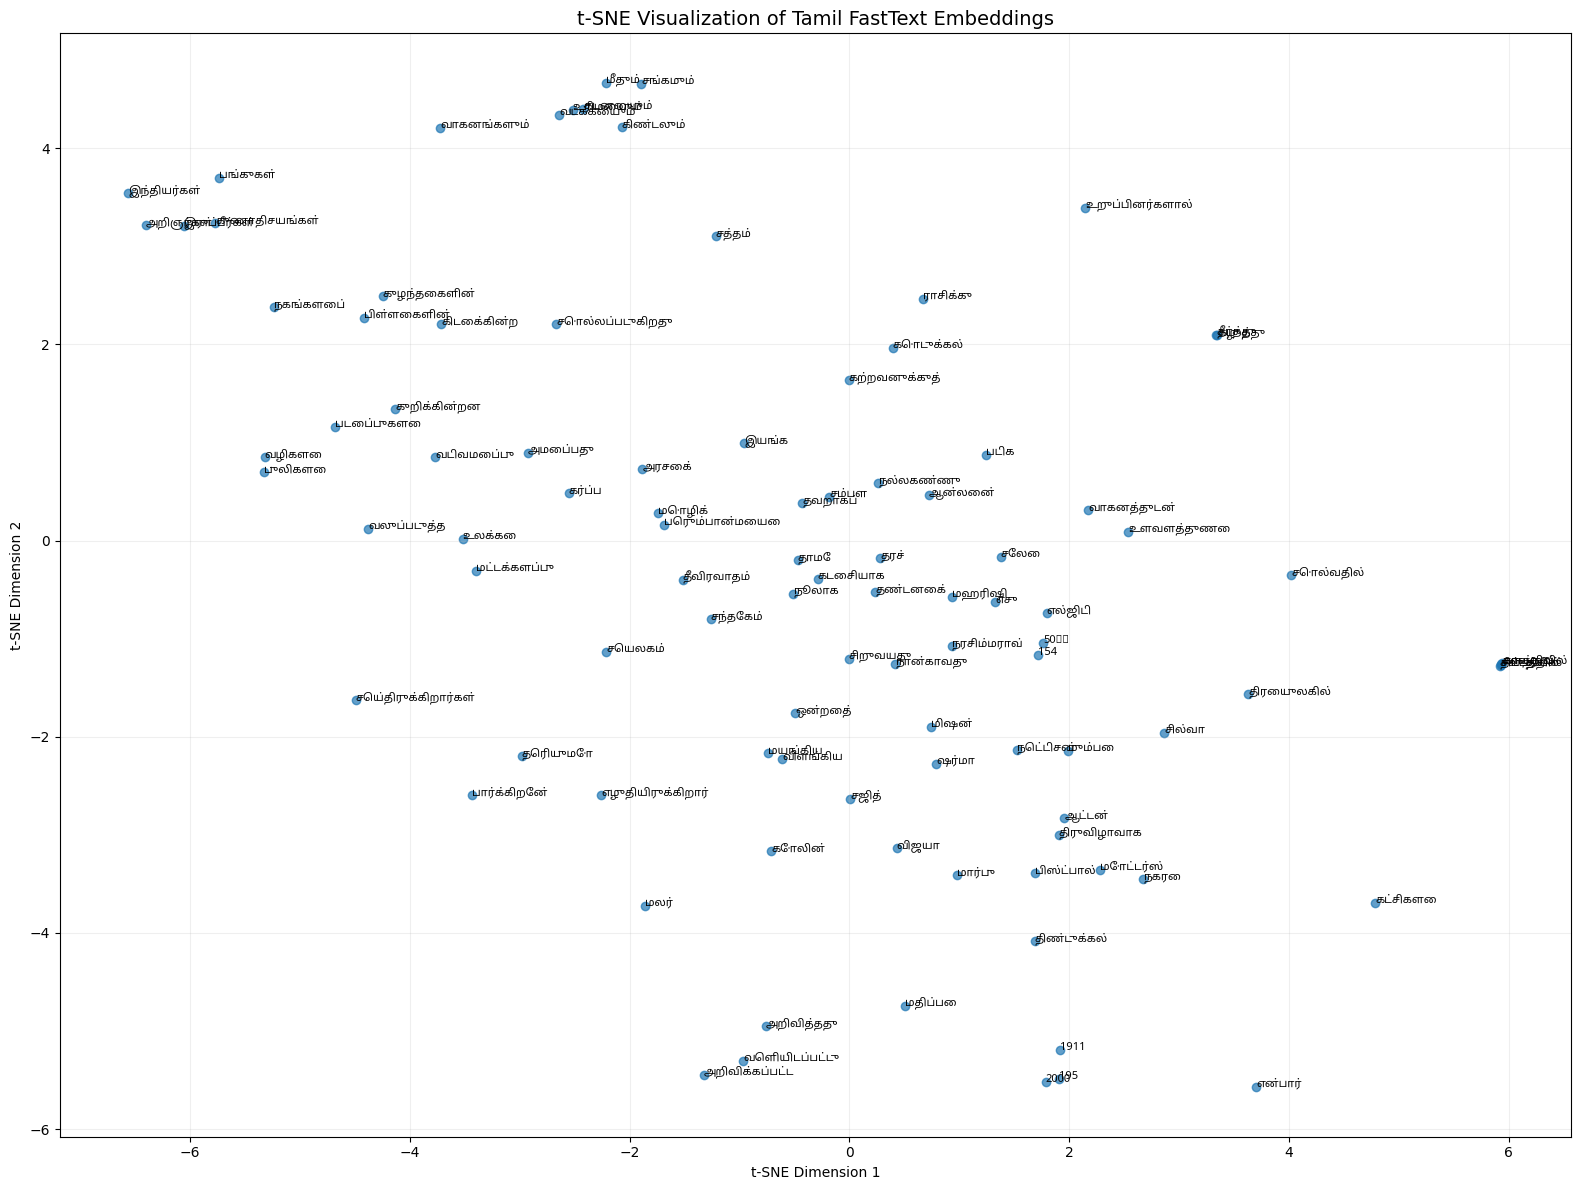

Saved: FOVL_Project/evaluation/tsne_plots/Tamil_tsne.png

Processing: Telugu


/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Telugu.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Telugu.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:104: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Telugu.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/tmp/ipykernel_675/309947929.py:104: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Telugu.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Telugu.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Telugu.
  fig.canvas.print_figure(bytes_io, **kw)


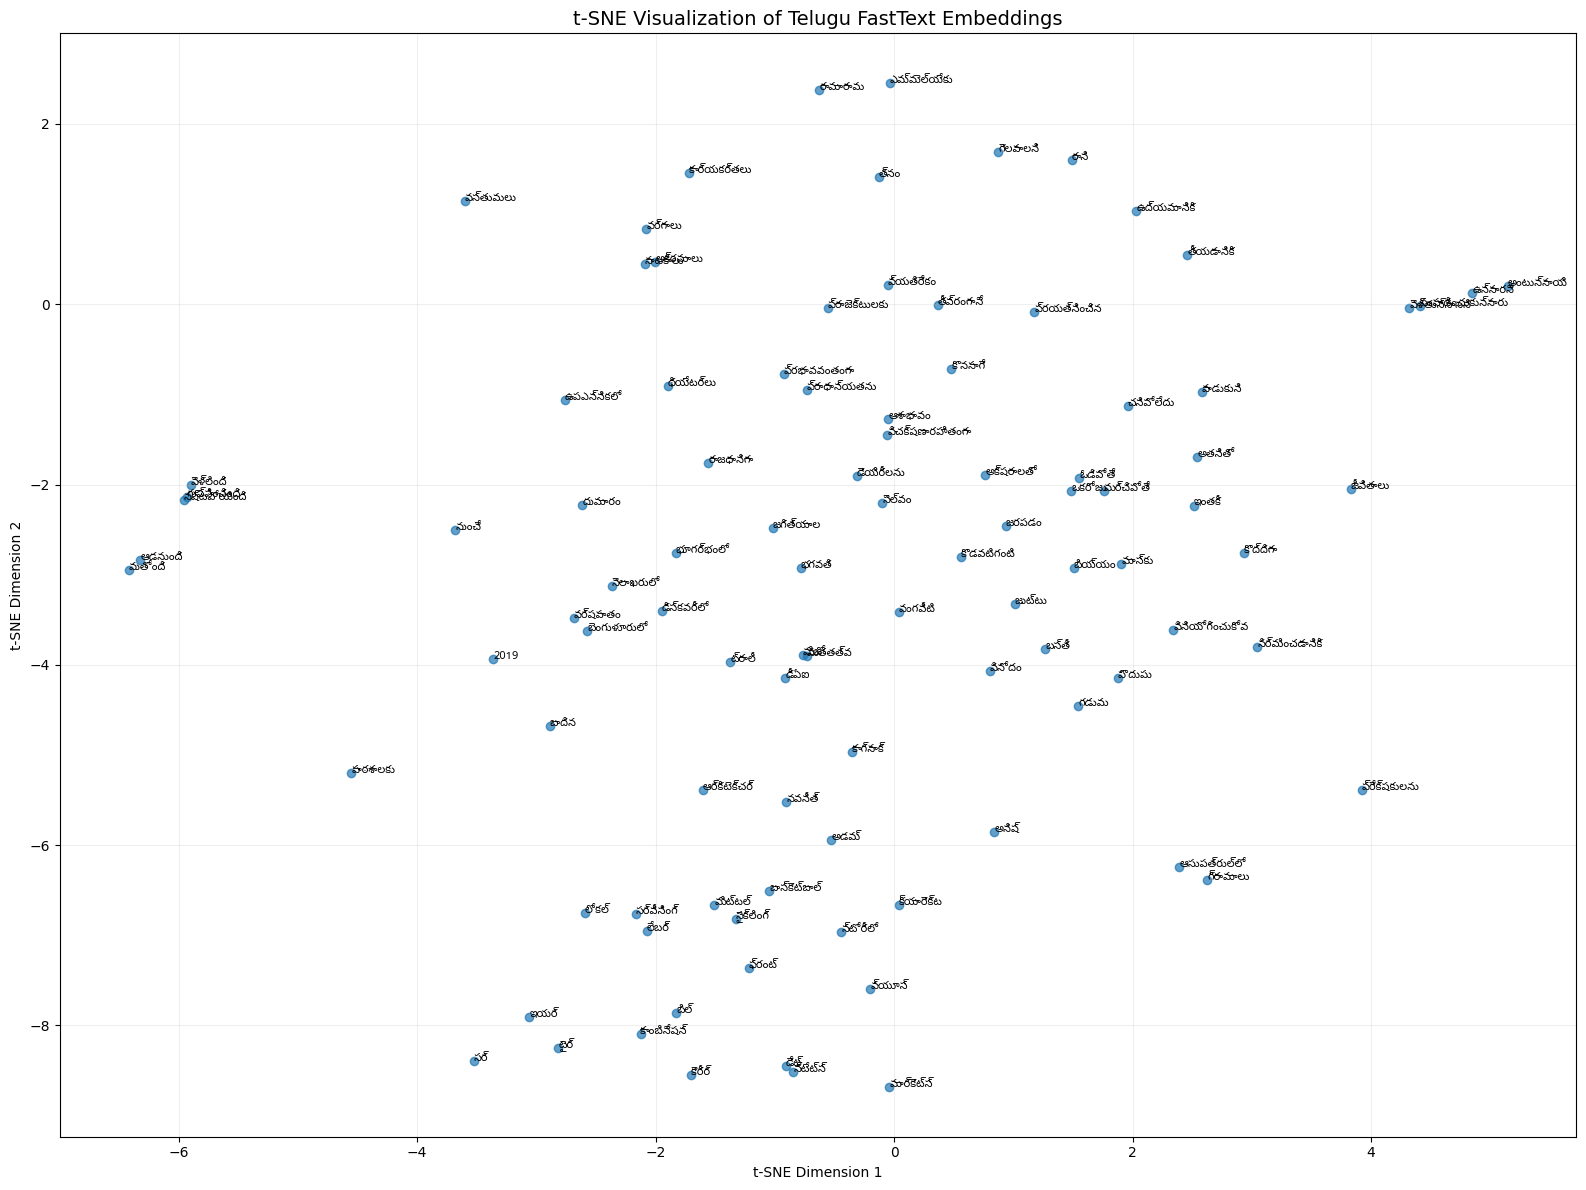

Saved: FOVL_Project/evaluation/tsne_plots/Telugu_tsne.png

Processing: Urdu


/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 108 (l) missing from font(s) Noto Naskh Arabic.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:98: UserWarning: Glyph 112 (p) missing from font(s) Noto Naskh Arabic.
  plt.tight_layout()
/tmp/ipykernel_675/309947929.py:104: UserWarning: Glyph 108 (l) missing from font(s) Noto Naskh Arabic.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/tmp/ipykernel_675/309947929.py:104: UserWarning: Glyph 112 (p) missing from font(s) Noto Naskh Arabic.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 108 (l) missing from font(s) Noto Naskh Arabic.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 112 (p) missing from font(s) Noto Naskh Arabic.
  fig.canvas.print_figure(bytes_io, **kw)


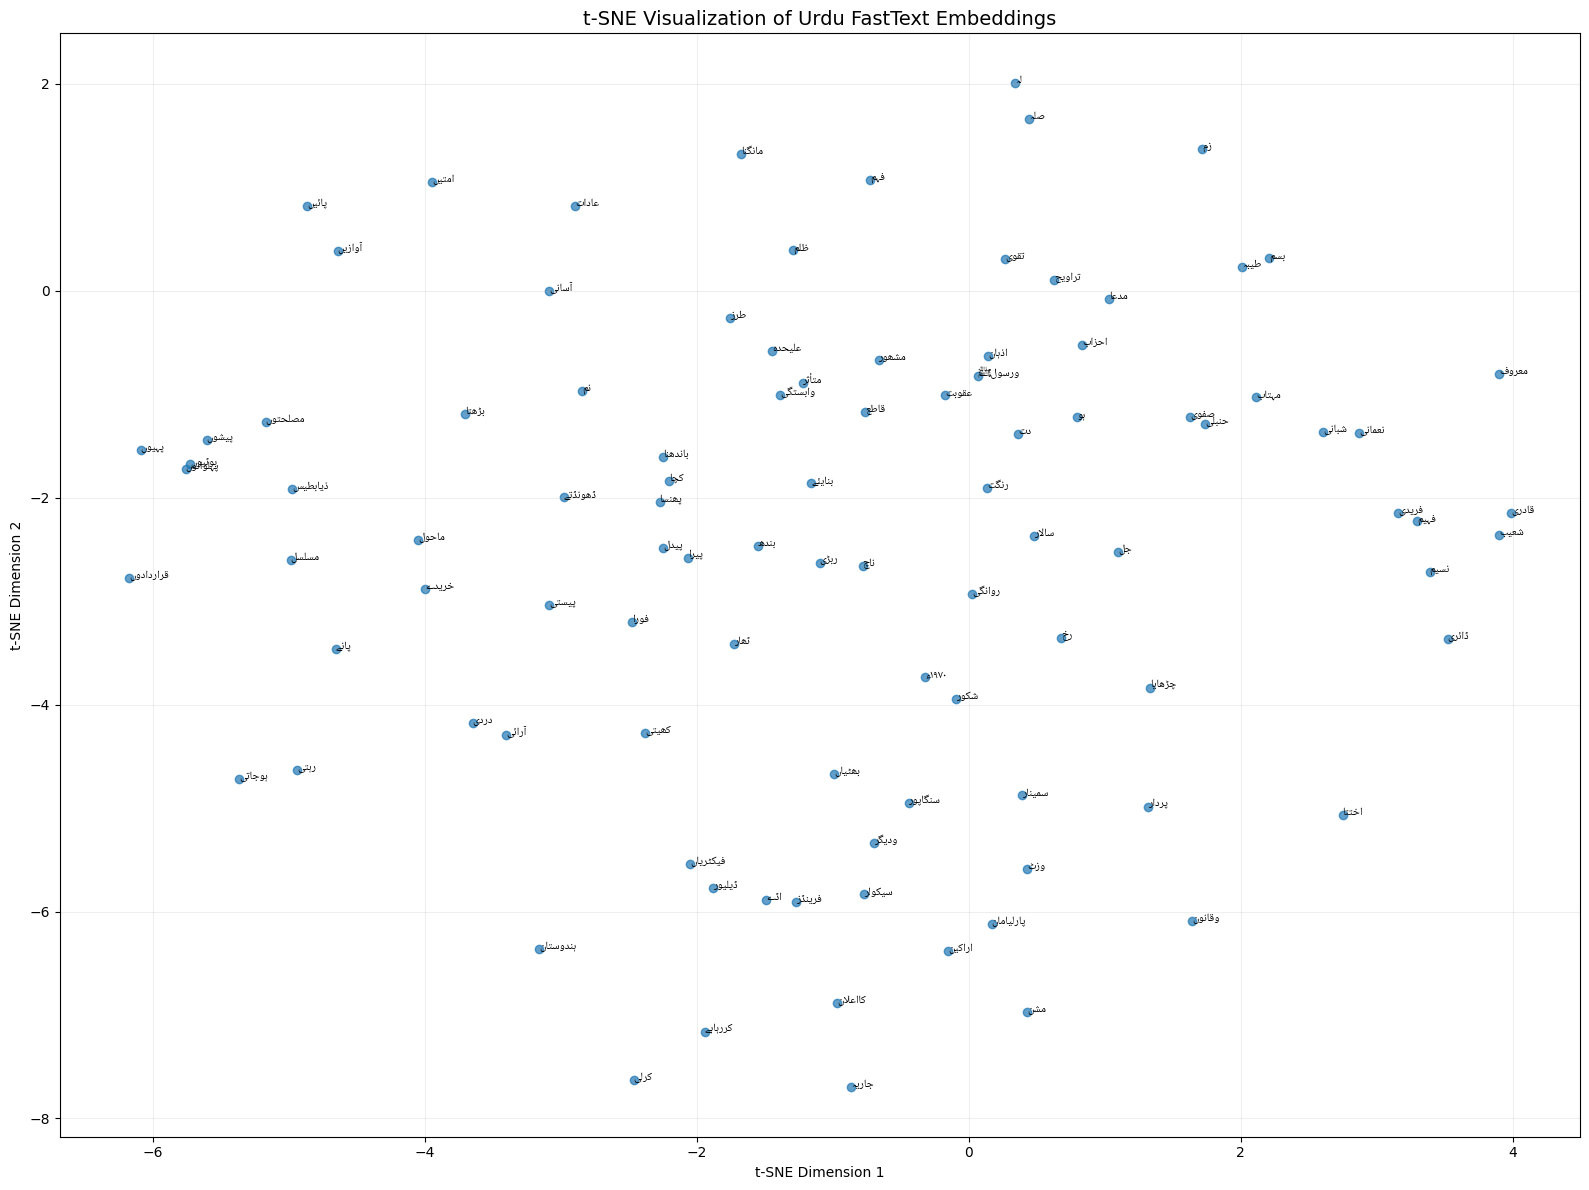

Saved: FOVL_Project/evaluation/tsne_plots/Urdu_tsne.png

All seven t-SNE visualizations completed!


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from sklearn.manifold import TSNE
from gensim.models import FastText
import arabic_reshaper
from bidi.algorithm import get_display

languages = [
    "Gujarati", "Hindi", "Marathi",
    "Punjabi", "Tamil", "Telugu", "Urdu"
]

font_paths = {
    "Gujarati": "/usr/share/fonts/truetype/noto/NotoSansGujarati-Regular.ttf",
    "Hindi": "/usr/share/fonts/truetype/noto/NotoSansDevanagari-Regular.ttf",
    "Marathi": "/usr/share/fonts/truetype/noto/NotoSansDevanagari-Regular.ttf",
    "Punjabi": "/usr/share/fonts/truetype/noto/NotoSansGurmukhi-Regular.ttf",
    "Tamil": "/usr/share/fonts/truetype/noto/NotoSansTamil-Regular.ttf",
    "Telugu": "/usr/share/fonts/truetype/noto/NotoSansTelugu-Regular.ttf",
    "Urdu": "/usr/share/fonts/truetype/noto/NotoNaskhArabic-Regular.ttf"
}

tsne_dir = "FOVL_Project/evaluation/tsne_plots"
os.makedirs(tsne_dir, exist_ok=True)

for language in languages:

    print("\nProcessing:", language)

    model_path = (
        "FOVL_Project/models/"
        + language.replace(" ", "_")
        + "_fasttext.model"
    )

    model = FastText.load(model_path)

    vocabulary = model.wv.index_to_key
    rng = np.random.default_rng(42)

    selected_words = rng.choice(
        vocabulary, size=100, replace=False
    ).tolist()

    vectors = np.array([
        model.wv[word] for word in selected_words
    ])

    tsne = TSNE(
        n_components=2,
        perplexity=30,
        random_state=42,
        init="pca",
        learning_rate="auto"
    )

    reduced_vectors = tsne.fit_transform(vectors)

    # Separate font properties
    indic_font = fm.FontProperties(fname=font_paths[language])
    english_font = fm.FontProperties(family="DejaVu Sans")

    plt.figure(figsize=(16, 12))
    plt.scatter(
        reduced_vectors[:, 0],
        reduced_vectors[:, 1],
        alpha=0.7
    )

    for i, word in enumerate(selected_words):

        display_word = word

        if language == "Urdu":
            display_word = get_display(
                arabic_reshaper.reshape(word)
            )

        plt.annotate(
            display_word,
            (reduced_vectors[i, 0], reduced_vectors[i, 1]),
            fontproperties=indic_font,
            fontsize=8
        )

    plt.title(
        f"t-SNE Visualization of {language} FastText Embeddings",
        fontproperties=english_font,
        fontsize=14
    )

    plt.xlabel("t-SNE Dimension 1", fontproperties=english_font)
    plt.ylabel("t-SNE Dimension 2", fontproperties=english_font)

    plt.grid(alpha=0.2)
    plt.tight_layout()

    save_path = os.path.join(
        tsne_dir, language + "_tsne.png"
    )

    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved:", save_path)

print("\nAll seven t-SNE visualizations completed!")

In [ ]:

import os
import json
import numpy as np
from gensim.models import FastText

languages = [
    "Gujarati", "Hindi", "Marathi",
    "Punjabi", "Tamil", "Telugu", "Urdu"
]

# Create vocabulary directory
vocab_dir = "FOVL_Project/evaluation/vocabulary"
os.makedirs(vocab_dir, exist_ok=True)

# Save vocabulary mappings
vocabulary_mappings = {}

for language in languages:

    model_path = (
        "FOVL_Project/models/"
        + language.replace(" ", "_")
        + "_fasttext.model"
    )

    model = FastText.load(model_path)

    vocabulary_mappings[language] = model.wv.key_to_index

    print(
        language,
        "- Vocabulary size:",
        len(model.wv.key_to_index)
    )

# Save all mappings in one JSON file
mapping_path = os.path.join(
    vocab_dir, "vocabulary_mappings.json"
)

with open(mapping_path, "w", encoding="utf-8") as f:
    json.dump(
        vocabulary_mappings,
        f,
        ensure_ascii=False,
        indent=2
    )

print("\nVocabulary mappings saved:", mapping_path)

# Find and verify all NPY files
print("\nSearching for embedding files...")

npy_files = {}

for root, dirs, files in os.walk("FOVL_Project"):
    for filename in files:
        if filename.endswith(".npy"):
            for language in languages:
                if filename.lower().startswith(language.lower()):
                    npy_files[language] = os.path.join(root, filename)

# Verify each language
print("\nEMBEDDING FILE VERIFICATION")

for language in languages:

    if language not in npy_files:
        print(language, "- FILE NOT FOUND")
        continue

    path = npy_files[language]
    vectors = np.load(path)

    print("\nLanguage:", language)
    print("File:", path)
    print("Shape:", vectors.shape)
    print("Expected dimensions:", "(N, 2, 300)")
    print("Correct shape:", vectors.ndim == 3 and
          vectors.shape[1:] == (2, 300))
    print("All finite:", np.isfinite(vectors).all())

print("\nStep 9 verification completed!")


Gujarati - Vocabulary size: 15400
Hindi - Vocabulary size: 12786
Marathi - Vocabulary size: 16882
Punjabi - Vocabulary size: 12586
Tamil - Vocabulary size: 17520
Telugu - Vocabulary size: 16516
Urdu - Vocabulary size: 14183

Vocabulary mappings saved: FOVL_Project/evaluation/vocabulary/vocabulary_mappings.json

Searching for embedding files...

EMBEDDING FILE VERIFICATION

Language: Gujarati
File: FOVL_Project/evaluation/Gujarati_embeddings.npy
Shape: (162, 2, 300)
Expected dimensions: (N, 2, 300)
Correct shape: True
All finite: True

Language: Hindi
File: FOVL_Project/evaluation/Hindi_embeddings.npy
Shape: (235, 2, 300)
Expected dimensions: (N, 2, 300)
Correct shape: True
All finite: True

Language: Marathi
File: FOVL_Project/evaluation/Marathi_embeddings.npy
Shape: (104, 2, 300)
Expected dimensions: (N, 2, 300)
Correct shape: True
All finite: True

Language: Punjabi
File: FOVL_Project/evaluation/Punjabi_embeddings.npy
Shape: (143, 2, 300)
Expected dimensions: (N, 2, 300)
Correct shap

In [ ]:

import os

print("Current project folders:")
for root, dirs, files in os.walk("FOVL_Project"):
    if root.count(os.sep) <= 3:
        print("\nFolder:", root)
        for file in files[:10]:
            print("  ", file)

print("\nPossible benchmark-related variables:")
for name in globals():
    if any(word in name.lower() for word in ["benchmark", "similarity", "evaluation", "dataset"]):
        print(name, type(globals()[name]))


Current project folders:

Folder: FOVL_Project
   dataset_info.txt

Folder: FOVL_Project/processed_data
   English.json
   Manipuri.json
   Telugu.json
   Maithili.json
   Santali.json
   Tamil.json
   Dogri.json
   Sindhi.json
   Konkani_(Goan).json
   Kannada.json

Folder: FOVL_Project/models
   Gujarati_fasttext.model.wv.vectors_ngrams.npy
   Hindi_fasttext.model
   Gujarati_fasttext.model
   Santali_fasttext.model
   Khasi_fasttext.model.wv.vectors_ngrams.npy
   Konkani_(Goan)_fasttext.model.wv.vectors_ngrams.npy
   Odia_fasttext.model.wv.vectors_ngrams.npy
   Urdu_fasttext.model.wv.vectors_ngrams.npy
   Manipuri_fasttext.model
   Santali_fasttext.model.wv.vectors_ngrams.npy

Folder: FOVL_Project/evaluation
   Tamil_embeddings.npy
   Telugu_embeddings.npy
   Hindi_embeddings.npy
   Marathi_embeddings.npy
   Urdu_embeddings.npy
   Gujarati_embeddings.npy
   Punjabi_embeddings.npy
   results.csv

Folder: FOVL_Project/evaluation/vocabulary
   vocabulary_mappings.json

Folder: FOVL_Pro

In [ ]:

# Inspect the structure of benchmark_data

print("Benchmark languages:")
print(list(benchmark_data.keys()))

print("\nDetails of each benchmark dataset:")

for language, data in benchmark_data.items():
    print("\n" + "="*50)
    print("Language:", language)
    print("Data type:", type(data))

    if hasattr(data, "columns"):
        print("Columns:", data.columns.tolist())
        print("Number of rows:", len(data))
        display(data.head(5))

    elif isinstance(data, list):
        print("Number of rows:", len(data))
        print("First 5 entries:")
        for item in data[:5]:
            print(item)

    else:
        print(data)


Benchmark languages:
['Gujarati', 'Hindi', 'Marathi', 'Punjabi', 'Tamil', 'Telugu', 'Urdu']

Details of each benchmark dataset:

Language: Gujarati
Data type: <class 'pandas.core.frame.DataFrame'>
Columns: ['word1', 'word2', 'human_score']
Number of rows: 162


,word1,word2,human_score
0,પ્રેમ,સેક્સ,8.00
1,વાઘ,બિલાડી,7.50
2,વાઘ,વાઘ,10.00
3,પુસ્તક,કાગળ,7.25
4,કમ્પ્યુટર,કીબોર્ડ,8.00



Language: Hindi
Data type: <class 'pandas.core.frame.DataFrame'>
Columns: ['word1', 'word2', 'human_score']
Number of rows: 235


,word1,word2,human_score
0,मोहब्बत,सेक्स,6.8
1,बाघ,बिल्ली,7.0
2,किताब,कागज़,7.6
3,कंप्यूटर,कीबोर्ड,7.6
4,कंप्यूटर,इंटरनेट,8.0



Language: Marathi
Data type: <class 'pandas.core.frame.DataFrame'>
Columns: ['word1', 'word2', 'human_score']
Number of rows: 104


,word1,word2,human_score
0,वाघ,मांजर,7.000
1,वाघ,वाघ,10.000
2,पुस्तक,कागद,7.375
3,संगणक,कळफलक,8.000
4,संगणक,इंटरनेट,8.500


... (4 outputs left out)


Language: Telugu
Data type: <class 'pandas.core.frame.DataFrame'>
Columns: ['word1', 'word2', 'human_score']
Number of rows: 111


,word1,word2,human_score
0,పులి,పిల్లి,6.0
1,టైగర్,టైగర్,10.0
2,పుస్తక,కాగితం,8.0
3,కంప్యూటర్,కీబోర్డు,5.0
4,కంప్యూటర్,ఇంటర్నెట్,6.0



Language: Urdu
Data type: <class 'pandas.core.frame.DataFrame'>
Columns: ['word1', 'word2', 'human_score']
Number of rows: 100


,word1,word2,human_score
0,محبت,جنس,5.0
1,کتاب,کاغذ,9.0
2,کمپیوٹر,کی بورڈ,9.0
3,کمپیوٹر,انٹرنیٹ,8.0
4,ہوائی جہاز,گاڑی,4.0


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
from scipy.stats import spearmanr

analysis_data = {}

for language, df_bench in benchmark_data.items():

    model = evaluation_models[language]
    records = []

    for _, row in df_bench.iterrows():

        word1 = str(row["word1"])
        word2 = str(row["word2"])
        human_score = float(row["human_score"])

        # Generate embeddings using our existing OOV strategy
        vector1, _ = get_word_embedding(word1, model)
        vector2, _ = get_word_embedding(word2, model)

        # Calculate cosine similarity
        predicted_score = cosine_similarity(
            vector1.reshape(1, -1),
            vector2.reshape(1, -1)
        )[0, 0]

        records.append({
            "language": language,
            "word1": word1,
            "word2": word2,
            "human_score": human_score,
            "predicted_cosine": float(predicted_score)
        })

    result_df = pd.DataFrame(records)

    # Compare rankings rather than raw scores,
    # because human scores and cosine scores use different scales.
    result_df["human_rank"] = result_df["human_score"].rank(
        method="average", pct=True
    )

    result_df["model_rank"] = result_df["predicted_cosine"].rank(
        method="average", pct=True
    )

    result_df["rank_difference"] = abs(
        result_df["human_rank"] - result_df["model_rank"]
    )

    analysis_data[language] = result_df

    print(
        language,
        "| Pairs:", len(result_df),
        "| Spearman:",
        round(
            spearmanr(
                result_df["human_score"],
                result_df["predicted_cosine"]
            ).statistic,
            4
        )
    )

print("\nSimilarity calculations completed for all languages.")


Gujarati | Pairs: 162 | Spearman: 0.2862
Hindi | Pairs: 235 | Spearman: 0.1645
Marathi | Pairs: 104 | Spearman: 0.1557
Punjabi | Pairs: 143 | Spearman: 0.3698
Tamil | Pairs: 97 | Spearman: 0.3808
Telugu | Pairs: 111 | Spearman: 0.1877
Urdu | Pairs: 100 | Spearman: 0.2182

Similarity calculations completed for all languages.


In [ ]:
# Combine all seven language results
all_results = pd.concat(
    analysis_data.values(),
    ignore_index=True
)

In [ ]:

print("Checking variables...")

print("analysis_data exists:", "analysis_data" in globals())

if "analysis_data" in globals():
    print("Languages:", list(analysis_data.keys()))

    for language, data in analysis_data.items():
        print(language, "Rows:", len(data))
else:
    print("analysis_data was not created. Please rerun Step 10B.")


Checking variables...
analysis_data exists: True
Languages: ['Gujarati', 'Hindi', 'Marathi', 'Punjabi', 'Tamil', 'Telugu', 'Urdu']
Gujarati Rows: 162
Hindi Rows: 235
Marathi Rows: 104
Punjabi Rows: 143
Tamil Rows: 97
Telugu Rows: 111
Urdu Rows: 100


In [ ]:

import pandas as pd
import numpy as np

# Combine results from all seven languages
all_results = pd.concat(
    list(analysis_data.values()),
    ignore_index=True
)

print("Total benchmark pairs:", len(all_results))

# Remove identical word pairs
different_words = all_results[
    all_results["word1"] != all_results["word2"]
].copy()

# Calculate ranking differences
different_words["human_rank"] = different_words[
    "human_score"
].rank(method="average", pct=True)

different_words["model_rank"] = different_words[
    "predicted_cosine"
].rank(method="average", pct=True)

different_words["rank_difference"] = abs(
    different_words["human_rank"] -
    different_words["model_rank"]
)

# Select five best and five worst examples
best = different_words.nsmallest(5, "rank_difference").copy()
worst = different_words.nlargest(5, "rank_difference").copy()

best["prediction_type"] = "Good agreement"
worst["prediction_type"] = "Poor agreement"

# Combine selected examples
report_examples = pd.concat([best, worst], ignore_index=True)

# Select columns
report_examples = report_examples[
    [
        "language",
        "word1",
        "word2",
        "human_score",
        "predicted_cosine",
        "prediction_type",
        "rank_difference"
    ]
]

# Print results
print("\n========== 10 WORD-PAIR EXAMPLES ==========\n")
print(report_examples.round(4).to_string(index=False))

# Save results
output_path = "FOVL_Project/evaluation/analysis_examples.csv"

report_examples.to_csv(output_path, index=False)

print("\n==========================================")
print("Total selected examples:", len(report_examples))
print("File saved successfully:", output_path)


Total benchmark pairs: 952

========== 10 WORD-PAIR EXAMPLES ==========

language      word1     word2  human_score  predicted_cosine prediction_type  rank_difference
    Urdu ہوائی جہاز      گاڑی        4.000            0.5958  Good agreement           0.0005
    Urdu       پینے       کان        0.250            0.4024  Good agreement           0.0011
 Marathi       रत्न  रत्नजडित        9.375            0.9627  Good agreement           0.0016
   Hindi       पीना      मुंह        7.000            0.7801  Good agreement           0.0027
  Telugu   జెరూసలేం ఇజ్రాయెల్        9.000            0.9180  Good agreement           0.0027
    Urdu        منی      گہنا        9.500            0.4279  Poor agreement           0.9528
Gujarati      વિલંબ   જાતિવાદ        0.000            0.9268  Poor agreement           0.9502
   Tamil   டென்னிஸ்     மோசடி        0.000            0.9253  Poor agreement           0.9449
   Hindi       पैसे        धन        9.200            0.4597  Poor agreement     

In [ ]:

import pandas as pd
import numpy as np

# Combine all language results
all_results = pd.concat(
    list(analysis_data.values()),
    ignore_index=True
)

# Remove identical word pairs
all_results = all_results[
    all_results["word1"] != all_results["word2"]
].copy()

# Calculate rankings separately for each language
all_results["human_rank"] = (
    all_results.groupby("language")["human_score"]
    .rank(method="average", pct=True)
)

all_results["model_rank"] = (
    all_results.groupby("language")["predicted_cosine"]
    .rank(method="average", pct=True)
)

# Calculate ranking difference
all_results["rank_difference"] = abs(
    all_results["human_rank"] -
    all_results["model_rank"]
)

# Select five best and five worst examples
best = all_results.nsmallest(5, "rank_difference").copy()
worst = all_results.nlargest(5, "rank_difference").copy()

best["prediction_type"] = "Good agreement"
worst["prediction_type"] = "Poor agreement"

# Combine examples
report_examples = pd.concat(
    [best, worst],
    ignore_index=True
)

# Select report columns
report_examples = report_examples[
    [
        "language",
        "word1",
        "word2",
        "human_score",
        "predicted_cosine",
        "prediction_type",
        "rank_difference"
    ]
]

print("CORRECTED ANALYSIS EXAMPLES\n")
print(report_examples.round(4).to_string(index=False))

# Save corrected results
report_examples.to_csv(
    "FOVL_Project/evaluation/analysis_examples.csv",
    index=False
)

print("\nCorrected examples saved successfully.")


CORRECTED ANALYSIS EXAMPLES

language      word1     word2  human_score  predicted_cosine prediction_type  rank_difference
Gujarati        ફોન     સાધનો          7.0            0.7421  Good agreement           0.0000
 Punjabi        ਲਾਭ    ਨੁਕਸਾਨ          6.0            0.7101  Good agreement           0.0000
   Tamil மருத்துவர் செவிலியர்          7.5            0.8436  Good agreement           0.0000
   Hindi      दर्शक    सीरियल          7.6            0.7928  Good agreement           0.0021
 Punjabi ਰਜਿਸਟਰੇਸ਼ਨ    ਪ੍ਰਬੰਧ          5.0            0.6342  Good agreement           0.0035
   Hindi       पैसे        धन          9.2            0.4597  Poor agreement           0.9277
   Tamil   டென்னிஸ்     மோசடி          0.0            0.9253  Poor agreement           0.9140
   Hindi       पैसे    मुद्रा          8.6            0.4456  Poor agreement           0.9085
 Marathi    चित्रपट   समीक्षक          8.5            0.4979  Poor agreement           0.8981
Gujarati      વિલંબ   જાતિવાદ  

In [ ]:

print("Earlier evaluation results:")
for language, result in evaluation_results.items():
    print(language, result)

print("\nNew evaluation results:")
for language, data in analysis_data.items():
    print(
        language,
        round(
            data["human_score"].corr(
                data["predicted_cosine"],
                method="spearman"
            ),
            6
        )
    )


Earlier evaluation results:
Gujarati {'pairs': 162, 'spearman': np.float64(0.28615571254426514), 'p_value': np.float64(0.00022296885561307866), 'oov_words': 56, 'total_words': 324, 'coverage': 82.71604938271605, 'embeddings': array([[[ 4.81446594e-04,  4.47120786e-01,  1.79095030e-01, ...,
          1.66150182e-01, -1.24153346e-01,  6.50731698e-02],
        [-9.41307396e-02,  3.48123968e-01, -4.98366281e-02, ...,
          9.04783905e-02,  5.61304018e-02, -3.37718846e-03]],

       [[-4.79424261e-02,  3.57955605e-01,  1.80595946e-02, ...,
          7.00832531e-02, -1.62228364e-02,  5.24549522e-02],
        [-8.73663500e-02,  3.94902468e-01, -3.37821916e-02, ...,
          2.95003969e-02, -7.96725675e-02,  8.86530280e-02]],

       [[-4.79424261e-02,  3.57955605e-01,  1.80595946e-02, ...,
          7.00832531e-02, -1.62228364e-02,  5.24549522e-02],
        [-4.79424261e-02,  3.57955605e-01,  1.80595946e-02, ...,
          7.00832531e-02, -1.62228364e-02,  5.24549522e-02]],

       ...,


In [ ]:

import os
import pandas as pd

project_dir = "FOVL_Project"
tsne_dir = os.path.join(project_dir, "evaluation", "tsne_plots")
evaluation_dir = os.path.join(project_dir, "evaluation")

languages = [
    "Gujarati", "Hindi", "Marathi", "Punjabi",
    "Tamil", "Telugu", "Urdu"
]

print("Checking report files...\n")

for language in languages:
    plot_path = os.path.join(tsne_dir, f"{language}_tsne.png")
    print(
        f"{language}:",
        "FOUND" if os.path.exists(plot_path) else "MISSING"
    )

print("\nChecking evaluation files:")

for filename in ["results.csv", "analysis_examples.csv"]:
    path = os.path.join(evaluation_dir, filename)
    print(
        filename + ":",
        "FOUND" if os.path.exists(path) else "MISSING"
    )

print("\nResults CSV preview:")
results_path = os.path.join(evaluation_dir, "results.csv")

if os.path.exists(results_path):
    display(pd.read_csv(results_path))


Checking report files...

Gujarati: FOUND
Hindi: FOUND
Marathi: FOUND
Punjabi: FOUND
Tamil: FOUND
Telugu: FOUND
Urdu: FOUND

Checking evaluation files:
results.csv: FOUND
analysis_examples.csv: FOUND

Results CSV preview:


,Language,Pairs,Spearman,P-value,OOV Words,Total Words,Coverage (%)
0,Gujarati,162,0.286156,0.000223,56,324,82.716049
1,Hindi,235,0.164540,0.011532,91,470,80.638298
2,Marathi,104,0.155686,0.114533,56,208,73.076923
3,Punjabi,143,0.369846,0.000005,41,286,85.664336
4,Tamil,97,0.380825,0.000119,38,194,80.412371
5,Telugu,111,0.187715,0.048509,65,222,70.720721
6,Urdu,100,0.218156,0.029223,27,200,86.500000
